In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Librerías cargadas correctamente")


Librerías cargadas correctamente


In [ ]:
# 1. Definir la ruta del archivo
ruta_listings = "/content/drive/MyDrive/listings.csv"

# 2. Verificar que el archivo exista
if not os.path.isfile(ruta_listings):
    raise FileNotFoundError(f"No se encontró el archivo: {ruta_listings}")

# 3. Cargar la base de datos
listings = pd.read_csv(ruta_listings, low_memory=False)

# 4. Revisar el tamaño y las dimensiones
print(f"Tamaño del archivo: {os.path.getsize(ruta_listings) / (1024**2):.2f} MB")
print(f"Registros: {listings.shape[0]:,}")
print(f"Variables: {listings.shape[1]}")

# 5. Mostrar las primeras observaciones
display(listings.head())

Tamaño del archivo: 51.62 MB
Registros: 19,505
Variables: 90


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,27841,https://www.airbnb.com/rooms/27841,20260914164224,2026-09-16,NaN,Rosales Luxury Large 2BR Boutique Apt,Amazing bright 135m2 (1350 sq ft) apartment l...,NaN,https://a0.muscache.com/pictures/38377482/1df3...,113734,...,4.81,4.93,4.81,112727.0,NaN,3,3,0,0,0.23
1,3043690,https://www.airbnb.com/rooms/3043690,20260914164224,2026-09-16,NaN,Room with a private,Located close to Parque Lourdes and within eas...,NaN,https://a0.muscache.com/pictures/46939629/35da...,15499337,...,4.63,4.63,4.50,NaN,NaN,2,0,2,0,0.05
2,3218908,https://www.airbnb.com/rooms/3218908,20260914164224,2026-09-16,NaN,"Nice vintage flat near to 93 park, well located","This flat is Inspired from the Vintage style, ...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,16300536,...,4.77,4.96,4.83,183725.0,NaN,1,1,0,0,1.09
3,3247862,https://www.airbnb.com/rooms/3247862,20260914164224,2026-09-16,NaN,Room Best Location Virrey Park,"This is a single room, a perfect starting poin...",NaN,https://a0.muscache.com/pictures/60803566/e7da...,3775838,...,4.50,4.50,4.50,142019.0,NaN,1,0,1,0,0.01
4,3263631,https://www.airbnb.com/rooms/3263631,20260914164224,2026-09-16,NaN,Private and comfortabe room for 2,"Room w/double bed, clean towels & sheets, clos...",NaN,https://a0.muscache.com/pictures/103053685/5a2...,16503059,...,5.00,4.94,4.94,NaN,NaN,1,0,1,0,1.75


Etapa 1. Auditoría de las variables de precio
Antes de limpiar los datos, necesitamos responder tres preguntas:
1. ¿Cuál columna representa el precio que queremos predecir?
2. ¿Hay columnas de precio que contienen exactamente la misma información?
3. ¿Qué tan dispersos están los precios y cuáles son los valores extremos que debemos investigar?

In [ ]:

# 1. Identificar todas las variables relacionadas con precios
columnas_precio = [
    col for col in listings.columns
    if "price" in col.lower()
]

print("VARIABLES DE PRECIO")
print("-" * 60)

for col in columnas_precio:
    print(f"\nColumna: {col}")
    print("Tipo de dato:", listings[col].dtype)
    print("Valores faltantes:", f"{listings[col].isna().mean() * 100:.2f}%")
    print("Ejemplos:", listings[col].dropna().head(3).tolist())


VARIABLES DE PRECIO
------------------------------------------------------------

Columna: price
Tipo de dato: object
Valores faltantes: 3.65%
Ejemplos: ['$274,830.78', '$71,692.74', '$137,358.40']

Columna: price_quote_checkin_date
Tipo de dato: object
Valores faltantes: 1.08%
Ejemplos: ['2027-04-01', '2026-09-16', '2027-01-05']

Columna: price_quote_checkout_date
Tipo de dato: object
Valores faltantes: 1.08%
Ejemplos: ['2027-04-29', '2026-10-16', '2027-01-10']

Columna: price_quote_total_price
Tipo de dato: float64
Valores faltantes: 3.65%
Ejemplos: [7695261.77, 2150782.22, 686792.0]

Columna: price_quote_price_per_night
Tipo de dato: float64
Valores faltantes: 3.65%
Ejemplos: [274830.78, 71692.74, 137358.4]

Columna: price_quote_raw
Tipo de dato: object
Valores faltantes: 1.08%
Ejemplos: ['{"quote": {"taxes": null, "currency": "COP", "date_match": null, "service_fee": null, "total_price": "7695261.765333333333333333332", "cleaning_fee": null, "is_available": true, "discount_amount":

Siguiente paso: comprobar si los precios son redundantes

In [ ]:
# 1. Convertir ambas columnas a valores numéricos
precio_anunciado = pd.to_numeric(
    listings["price"].astype("string")
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce"
)

precio_cotizado = pd.to_numeric(
    listings["price_quote_price_per_night"],
    errors="coerce"
)

# 2. Comparar los registros que tienen ambos precios
comparacion = pd.DataFrame({
    "precio_anunciado": precio_anunciado,
    "precio_cotizado": precio_cotizado
}).dropna()

# 3. Calcular las diferencias absolutas
comparacion["diferencia"] = (
    comparacion["precio_anunciado"] -
    comparacion["precio_cotizado"]
).abs()

# 4. Identificar si los precios coinciden
comparacion["coinciden"] = np.isclose(
    comparacion["precio_anunciado"],
    comparacion["precio_cotizado"],
    rtol=1e-9,
    atol=0.01
)

# 5. Mostrar los resultados
if not comparacion.empty:
    print("Registros comparables:", len(comparacion))
    print("Precios coincidentes:", comparacion["coinciden"].sum())
    print(
        "Porcentaje coincidente:",
        round(comparacion["coinciden"].mean() * 100, 2), "%"
    )
    print(
        "Diferencia absoluta mediana:",
        round(comparacion["diferencia"].median(), 2)
    )

    print("\nEjemplos de diferencias:")
    display(
        comparacion.loc[~comparacion["coinciden"]].head(10)
    )
else:
    print("No existen registros con ambos precios disponibles.")

Registros comparables: 18794
Precios coincidentes: 18794
Porcentaje coincidente: 100.0 %
Diferencia absoluta mediana: 0.0

Ejemplos de diferencias:


,precio_anunciado,precio_cotizado,diferencia,coinciden


identificar valores extremos

In [ ]:
print("ESTADÍSTICAS DEL PRECIO ANUNCIADO")

display(
    precio_anunciado.describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).to_frame("precio_anunciado").round(2)
)

print("\nPrecios iguales o inferiores a cero:",
      (precio_anunciado.dropna() <= 0).sum())

print("\nLos 15 precios más altos:")

indices_top = precio_anunciado.nlargest(15).index

display(
    listings.loc[
        indices_top,
        ["id", "name", "room_type", "property_type", "price"]
    ]
)

ESTADÍSTICAS DEL PRECIO ANUNCIADO


,precio_anunciado
count,18794.0
mean,292878.34
std,3849321.17
min,15402.26
1%,34161.16
5%,53773.33
25%,109815.88
50%,160772.0
75%,229487.75
95%,496605.6



Precios iguales o inferiores a cero: 0

Los 15 precios más altos:


,id,name,room_type,property_type,price
4199,53430617,Homey Loft in Usaquen,Entire home/apt,Entire serviced apartment,"$258,514,678.00"
18499,1730781899476422753,Hotel Sofi Ca Boutique,Private room,Room in hotel,"$232,260,501.00"
6696,872010695106019062,Habitación Cómoda,Private room,Private room in casa particular,"$224,768,226.24"
6577,860199176293876612,descanso tu casa.,Private room,Private room in home,"$217,800,411.23"
1572,29237840,Habitación Doble Privada en Hostal Yarumo,Private room,Private room in home,"$160,000,000.00"
3657,50090707,Maravilloso apartamento en zona historica - Bo...,Entire home/apt,Entire serviced apartment,"$150,025,000.00"
8203,1028861544612678160,Aparta estudio 402- Movistar-Corferias,Entire home/apt,Entire rental unit,"$95,000,000.00"
16361,1625557975532823153,Apto Parque la 93 Bogotá,Entire home/apt,Entire rental unit,"$16,800,000.00"
13284,1444331568470368931,"Aparta-Estudio Moderno en Bogotá, vista a montaña",Entire home/apt,Entire rental unit,"$12,070,000.00"
5493,714345990863818509,3.1.0 Alojamiento en Colombia,Private room,Private room in home,"$10,000,000.00"


Investiguemos los casos extremos

In [ ]:
import json

# 1. Seleccionar las variables necesarias para investigar los extremos
variables_revision = [
    "id", "name", "price", "price_quote_price_per_night",
    "price_quote_total_price", "price_quote_checkin_date",
    "price_quote_checkout_date", "accommodates", "bedrooms",
    "beds", "bathrooms", "room_type", "property_type",
    "minimum_nights", "maximum_nights", "availability_365",
    "estimated_occupancy_l365d", "estimated_revenue_l365d",
    "price_quote_raw"
]

# Verificar que las variables existan en la base de datos
variables_revision = [
    col for col in variables_revision
    if col in listings.columns
]

# 2. Seleccionar los 10 alojamientos con precios más altos
indices_extremos = precio_anunciado.nlargest(10).index

revision_extremos = listings.loc[
    indices_extremos, variables_revision
].copy()

# 3. Crear una función para extraer información de las cotizaciones
def extraer_cotizacion(valor):
    try:
        datos = json.loads(valor)
        quote = datos.get("quote", {})

        return pd.Series({
            "moneda": quote.get("currency"),
            "precio_noche_cotizacion": quote.get("price_per_night"),
            "es_tarifa_mensual": quote.get("is_monthly_priced"),
            "entrada_solicitada": quote.get("requested_checkin_date"),
            "salida_solicitada": quote.get("requested_checkout_date"),
            "disponible_cotizacion": quote.get("is_available")
        })

    except (TypeError, ValueError, AttributeError):
        return pd.Series({
            "moneda": None,
            "precio_noche_cotizacion": None,
            "es_tarifa_mensual": None,
            "entrada_solicitada": None,
            "salida_solicitada": None,
            "disponible_cotizacion": None
        })

# 4. Extraer la información de las cotizaciones
datos_cotizacion = revision_extremos["price_quote_raw"].apply(
    extraer_cotizacion
)

# 5. Integrar la información extraída
revision_extremos = pd.concat(
    [
        revision_extremos.drop(columns=["price_quote_raw"]),
        datos_cotizacion
    ],
    axis=1
)

# 6. Mostrar los resultados
display(revision_extremos)

,id,name,price,price_quote_price_per_night,price_quote_total_price,price_quote_checkin_date,price_quote_checkout_date,accommodates,bedrooms,beds,...,maximum_nights,availability_365,estimated_occupancy_l365d,estimated_revenue_l365d,moneda,precio_noche_cotizacion,es_tarifa_mensual,entrada_solicitada,salida_solicitada,disponible_cotizacion
4199,53430617,Homey Loft in Usaquen,"$258,514,678.00",2.585147e+08,5.170294e+08,2026-09-16,2026-09-18,2,1.0,1.0,...,365.0,365,6,1.551088e+09,COP,258514678,False,2026-09-16,2026-09-18,True
18499,1730781899476422753,Hotel Sofi Ca Boutique,"$232,260,501.00",2.322605e+08,2.322605e+08,2026-09-16,2026-09-17,2,1.0,3.0,...,365.0,360,0,0.000000e+00,COP,232260501,False,2026-09-16,2026-09-17,True
6696,872010695106019062,Habitación Cómoda,"$224,768,226.24",2.247682e+08,2.247682e+08,2026-09-16,2026-09-17,1,1.0,1.0,...,365.0,365,0,0.000000e+00,COP,224768226.24,False,2026-09-16,2026-09-17,True
6577,860199176293876612,descanso tu casa.,"$217,800,411.23",2.178004e+08,6.534012e+09,2026-09-16,2026-10-16,1,1.0,1.0,...,365.0,365,0,0.000000e+00,COP,217800411.2266666666666666667,True,2026-09-16,2026-10-16,True
1572,29237840,Habitación Doble Privada en Hostal Yarumo,"$160,000,000.00",1.600000e+08,1.600000e+08,2026-09-16,2026-09-17,2,1.0,1.0,...,1125.0,365,0,0.000000e+00,COP,160000000,False,2026-09-16,2026-09-17,True
3657,50090707,Maravilloso apartamento en zona historica - Bo...,"$150,025,000.00",1.500250e+08,6.001000e+08,2026-09-16,2026-09-20,3,1.0,3.0,...,1125.0,365,0,0.000000e+00,COP,150025000,False,2026-09-16,2026-09-20,True
8203,1028861544612678160,Aparta estudio 402- Movistar-Corferias,"$95,000,000.00",9.500000e+07,9.500000e+07,2026-11-01,2026-11-02,4,1.0,3.0,...,365.0,224,0,0.000000e+00,COP,95000000,False,2026-11-01,2026-11-02,True
16361,1625557975532823153,Apto Parque la 93 Bogotá,"$16,800,000.00",1.680000e+07,5.040000e+07,2026-09-16,2026-09-19,2,1.0,1.0,...,365.0,341,60,1.008000e+09,COP,16800000.00,False,2026-09-16,2026-09-19,True
13284,1444331568470368931,"Aparta-Estudio Moderno en Bogotá, vista a montaña","$12,070,000.00",1.207000e+07,1.207000e+07,2026-09-16,2026-09-17,3,1.0,2.0,...,1125.0,362,0,0.000000e+00,COP,12070000.00,False,2026-09-16,2026-09-17,True
5493,714345990863818509,3.1.0 Alojamiento en Colombia,"$10,000,000.00",1.000000e+07,1.000000e+07,2026-09-16,2026-09-17,2,1.0,1.0,...,365.0,365,0,0.000000e+00,COP,10000000,False,2026-09-16,2026-09-17,True


medir la calidad de los datos

In [ ]:
# AUDITORÍA INICIAL DE CALIDAD DE DATOS

# 1. Dimensiones originales de la base
print("DIMENSIONES ORIGINALES")
print(f"Filas: {listings.shape[0]:,}")
print(f"Columnas: {listings.shape[1]}")

# 2. Identificación de registros duplicados
print("\n1. REGISTROS DUPLICADOS")
print("Filas completamente duplicadas:", listings.duplicated().sum())
print("IDs duplicados:", listings["id"].duplicated().sum())

# 3. Identificación de valores faltantes
mascara_faltantes = listings.isna()

faltantes = pd.DataFrame({
    "faltantes": mascara_faltantes.sum(),
    "porcentaje": mascara_faltantes.mean() * 100
})

faltantes = faltantes[faltantes["faltantes"] > 0]
faltantes = faltantes.sort_values(
    "porcentaje", ascending=False
)

print("\n2. VARIABLES CON VALORES FALTANTES")
display(faltantes.round(2))

# 4. Identificación de columnas completamente vacías
columnas_vacias = listings.columns[
    mascara_faltantes.all()
].tolist()

print("\n3. COLUMNAS COMPLETAMENTE VACÍAS")
print(columnas_vacias)

# 5. Evaluación de la variable objetivo: precio
print("\n4. CALIDAD DE LA VARIABLE OBJETIVO")
print("Precios faltantes:", precio_anunciado.isna().sum())
print(
    "Precios iguales o inferiores a cero:",
    (precio_anunciado.dropna() <= 0).sum()
)
print(
    "Precios superiores a $5 millones:",
    (precio_anunciado > 5_000_000).sum()
)

DIMENSIONES ORIGINALES
Filas: 19,505
Columnas: 90

1. REGISTROS DUPLICADOS
Filas completamente duplicadas: 0
IDs duplicados: 0

2. VARIABLES CON VALORES FALTANTES


,faltantes,porcentaje
host_since,19505,100.00
neighborhood_overview,19505,100.00
host_thumbnail_url,19505,100.00
host_acceptance_rate,19505,100.00
host_response_rate,19505,100.00
host_response_time,19505,100.00
host_neighbourhood,19505,100.00
host_total_listings_count,19505,100.00
host_verifications,19505,100.00
neighbourhood,19505,100.00



3. COLUMNAS COMPLETAMENTE VACÍAS
['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'neighbourhood_group_cleansed', 'bathrooms', 'calendar_updated', 'instant_bookable']

4. CALIDAD DE LA VARIABLE OBJETIVO
Precios faltantes: 711
Precios iguales o inferiores a cero: 0
Precios superiores a $5 millones: 35


In [ ]:
# ETAPA 1. LIMPIEZA INICIAL DE DATOS

# 1. Crear una copia de la base original
listings_clean = listings.copy()

filas_iniciales = len(listings_clean)
columnas_iniciales = len(listings_clean.columns)

# 2. Eliminar columnas completamente vacías
columnas_vacias = listings_clean.columns[
    listings_clean.isna().all()
].tolist()

listings_clean = listings_clean.drop(columns=columnas_vacias)

# 3. Incorporar el precio en formato numérico
listings_clean["price_numeric"] = precio_anunciado.reindex(
    listings_clean.index
)

# 4. Separar registros sin precio para futuras predicciones
listings_sin_precio = listings_clean.loc[
    listings_clean["price_numeric"].isna()
].copy()

# 5. Crear la base para el entrenamiento supervisado
listings_clean = listings_clean.loc[
    listings_clean["price_numeric"].notna()
].copy()

# 6. Identificar precios extremos sin eliminarlos
listings_clean["precio_extremo_revision"] = (
    listings_clean["price_numeric"] > 5_000_000
)

# 7. Resumen de resultados
print("RESUMEN DE LIMPIEZA INICIAL")
print("-" * 45)
print(f"Registros originales: {filas_iniciales:,}")
print(f"Columnas originales: {columnas_iniciales}")
print(f"Columnas vacías eliminadas: {len(columnas_vacias)}")
print(f"Columnas restantes: {len(listings_clean.columns)}")
print(f"Registros separados sin precio: {len(listings_sin_precio):,}")
print(f"Registros para entrenamiento: {len(listings_clean):,}")
print(
    "Precios extremos pendientes de revisión:",
    int(listings_clean["precio_extremo_revision"].sum())
)

# 8. Mostrar las primeras observaciones
display(
    listings_clean[
        ["id", "name", "price", "price_numeric",
         "precio_extremo_revision"]
    ].head()
)

RESUMEN DE LIMPIEZA INICIAL
---------------------------------------------
Registros originales: 19,505
Columnas originales: 76
Columnas vacías eliminadas: 0
Columnas restantes: 78
Registros separados sin precio: 711
Registros para entrenamiento: 18,794
Precios extremos pendientes de revisión: 35


,id,name,price,price_numeric,precio_extremo_revision
0,27841,Rosales Luxury Large 2BR Boutique Apt,"$274,830.78",274830.78,False
1,3043690,Room with a private,"$71,692.74",71692.74,False
2,3218908,"Nice vintage flat near to 93 park, well located","$137,358.40",137358.4,False
3,3247862,Room Best Location Virrey Park,"$173,779.33",173779.33,False
4,3263631,Private and comfortabe room for 2,"$67,154.71",67154.71,False


In [ ]:
# INVESTIGACIÓN DE PRECIOS EXTREMOS

# 1. Variables relevantes para investigar los alojamientos
columnas_revision = [
    "id",
    "name",
    "price_numeric",
    "room_type",
    "property_type",
    "neighbourhood_cleansed",
    "latitude",
    "longitude",
    "accommodates",
    "bedrooms",
    "beds",
    "minimum_nights",
    "availability_365",
    "estimated_occupancy_l365d",
    "estimated_revenue_l365d"
]

# 2. Conservar únicamente las variables disponibles
columnas_revision = [
    col for col in columnas_revision
    if col in listings_clean.columns
]

# 3. Seleccionar y ordenar los precios extremos
extremos = (
    listings_clean.loc[
        listings_clean["precio_extremo_revision"],
        columnas_revision
    ]
    .sort_values("price_numeric", ascending=False)
)

# 4. Mostrar resultados
print("INVESTIGACIÓN DE PRECIOS EXTREMOS")
print("-" * 45)
print(f"Cantidad de alojamientos extremos: {len(extremos)}")

display(extremos)

INVESTIGACIÓN DE PRECIOS EXTREMOS
---------------------------------------------
Cantidad de alojamientos extremos: 35


,id,name,price_numeric,room_type,property_type,neighbourhood_cleansed,latitude,longitude,accommodates,bedrooms,beds,minimum_nights,availability_365,estimated_occupancy_l365d,estimated_revenue_l365d
4199,53430617,Homey Loft in Usaquen,258514678.0,Entire home/apt,Entire serviced apartment,Usaquen,4.691540,-74.051140,2,1.0,1.0,2.0,365,6,1.551088e+09
18499,1730781899476422753,Hotel Sofi Ca Boutique,232260501.0,Private room,Room in hotel,Teusaquillo,4.632940,-74.091720,2,1.0,3.0,1.0,360,0,0.000000e+00
6696,872010695106019062,Habitación Cómoda,224768226.24,Private room,Private room in casa particular,Barrios Unidos,4.681253,-74.075049,1,1.0,1.0,1.0,365,0,0.000000e+00
6577,860199176293876612,descanso tu casa.,217800411.23,Private room,Private room in home,Barrios Unidos,4.681217,-74.075705,1,1.0,1.0,30.0,365,0,0.000000e+00
1572,29237840,Habitación Doble Privada en Hostal Yarumo,160000000.0,Private room,Private room in home,Candelaria,4.596190,-74.070120,2,1.0,1.0,1.0,365,0,0.000000e+00
3657,50090707,Maravilloso apartamento en zona historica - Bo...,150025000.0,Entire home/apt,Entire serviced apartment,Santa Fe,4.603840,-74.070950,3,1.0,3.0,4.0,365,0,0.000000e+00
8203,1028861544612678160,Aparta estudio 402- Movistar-Corferias,95000000.0,Entire home/apt,Entire rental unit,Teusaquillo,4.627041,-74.079970,4,1.0,3.0,1.0,224,0,0.000000e+00
16361,1625557975532823153,Apto Parque la 93 Bogotá,16800000.0,Entire home/apt,Entire rental unit,Chapinero,4.677303,-74.053130,2,1.0,1.0,3.0,341,60,1.008000e+09
13284,1444331568470368931,"Aparta-Estudio Moderno en Bogotá, vista a montaña",12070000.0,Entire home/apt,Entire rental unit,Barrios Unidos,4.671710,-74.077496,3,1.0,2.0,1.0,362,0,0.000000e+00
5493,714345990863818509,3.1.0 Alojamiento en Colombia,10000000.0,Private room,Private room in home,Puente Aranda,4.615160,-74.102180,2,1.0,1.0,1.0,365,0,0.000000e+00


In [ ]:
# ANÁLISIS DE CONCENTRACIÓN DE PRECIOS EXTREMOS

# 1. Seleccionar alojamientos con precios extremos
extremos = listings_clean.loc[
    listings_clean["precio_extremo_revision"]
].copy()

# 2. Definir función para resumir los precios
def resumen_extremos(variable):
    return (
        extremos.groupby(variable)
        .agg(
            cantidad=("id", "count"),
            precio_minimo=("price_numeric", "min"),
            precio_mediano=("price_numeric", "median"),
            precio_maximo=("price_numeric", "max")
        )
        .sort_values("cantidad", ascending=False)
        .round(2)
    )

# 3. Análisis por tipo de alojamiento
print("PRECIOS EXTREMOS POR TIPO DE ALOJAMIENTO")
display(resumen_extremos("room_type"))

# 4. Análisis por barrio
print("\nPRECIOS EXTREMOS POR BARRIO")
display(resumen_extremos("neighbourhood_cleansed"))

# 5. Análisis por capacidad
print("\nPRECIOS EXTREMOS POR CAPACIDAD")
display(resumen_extremos("accommodates"))

PRECIOS EXTREMOS POR TIPO DE ALOJAMIENTO


,cantidad,precio_minimo,precio_mediano,precio_maximo
room_type,,,,
Entire home/apt,29,5676146.94,9025000.0,258514678.0
Private room,6,5445513.93,188900205.62,232260501.0



PRECIOS EXTREMOS POR BARRIO


,cantidad,precio_minimo,precio_mediano,precio_maximo
neighbourhood_cleansed,,,,
Chapinero,13,5676146.94,9002500.0,16800000.0
Teusaquillo,12,9025000.0,9025000.0,232260501.0
Barrios Unidos,3,12070000.0,217800411.23,224768226.24
Candelaria,1,160000000.0,160000000.0,160000000.0
Fontibon,1,9424657.0,9424657.0,9424657.0
Engativa,1,9007500.0,9007500.0,9007500.0
Puente Aranda,1,10000000.0,10000000.0,10000000.0
Santa Fe,1,150025000.0,150025000.0,150025000.0
Suba,1,5445513.93,5445513.93,5445513.93



PRECIOS EXTREMOS POR CAPACIDAD


,cantidad,precio_minimo,precio_mediano,precio_maximo
accommodates,,,,
2,22,5445513.93,9025000.0,258514678.0
3,5,9020000.0,9055000.0,150025000.0
4,3,6171000.0,6171000.0,95000000.0
1,2,217800411.23,221284318.74,224768226.24
6,2,9007500.0,9216078.5,9424657.0
5,1,5676146.94,5676146.94,5676146.94


In [ ]:
# DISTRIBUCIÓN DEL PRECIO POR TIPO DE ALOJAMIENTO

# Seleccionar precios válidos y positivos
precios_validos = listings_clean.loc[
    listings_clean["price_numeric"] > 0
].copy()

# 1. Estadísticas descriptivas según el tipo de alojamiento
resumen_precios = (
    precios_validos.groupby("room_type")["price_numeric"]
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95, 0.99])
)

print("DISTRIBUCIÓN DE PRECIOS POR TIPO DE ALOJAMIENTO")
display(resumen_precios.round(2))


# 2. Cantidad y porcentaje de precios superiores a diferentes umbrales
umbrales = [1_000_000, 2_000_000, 5_000_000, 10_000_000]

print("\nPRECIOS SUPERIORES A DIFERENTES UMBRALES")

for umbral in umbrales:
    cantidad = (precios_validos["price_numeric"] > umbral).sum()
    porcentaje = cantidad / len(precios_validos) * 100

    print(
        f"Precios superiores a ${umbral:,.0f} COP: "
        f"{cantidad:,} ({porcentaje:.2f}%)"
    )

DISTRIBUCIÓN DE PRECIOS POR TIPO DE ALOJAMIENTO


,count,mean,std,min,50%,75%,90%,95%,99%,max
room_type,,,,,,,,,,
Entire home/apt,13655.0,295298.31,2720773.66,27364.56,181250.0,256359.84,398550.9,546312.0,1628895.54,258514678.0
Hotel room,27.0,198868.56,91039.75,54459.74,195000.0,234134.5,306559.4,384892.0,422200.0,430000.0
Private room,4993.0,292378.93,5960917.5,15402.26,90000.0,136306.33,206983.8,278776.0,690096.0,232260501.0
Shared room,119.0,57476.34,44654.5,30000.0,40000.0,60000.0,86000.0,119814.95,265659.2,369800.0



PRECIOS SUPERIORES A DIFERENTES UMBRALES
Precios superiores a $1,000,000 COP: 258 (1.37%)
Precios superiores a $2,000,000 COP: 95 (0.51%)
Precios superiores a $5,000,000 COP: 35 (0.19%)
Precios superiores a $10,000,000 COP: 9 (0.05%)


In [ ]:

# ETAPA 2: TRATAMIENTO INICIAL DE PRECIOS EXTREMOS

umbral_precio = 5_000_000

# Guardar los casos excluidos para documentarlos
precios_excluidos = listings_clean.loc[
    listings_clean["price_numeric"] > umbral_precio
].copy()

# Crear la base de modelado sin esos casos
listings_model = listings_clean.loc[
    listings_clean["price_numeric"] <= umbral_precio
].copy()

print("RESULTADO DE LA LIMPIEZA DE PRECIOS")
print("-" * 45)
print("Base antes de esta etapa:", f"{len(listings_clean):,}")
print("Registros excluidos:", f"{len(precios_excluidos):,}")
print("Base para modelado:", f"{len(listings_model):,}")
print(
    "Porcentaje conservado:",
    f"{len(listings_model) / len(listings_clean) * 100:.2f}%"
)

print("\nESTADÍSTICAS DEL PRECIO DESPUÉS DE LA LIMPIEZA")
display(
    listings_model["price_numeric"]
    .describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .to_frame("precio_COP")
    .round(2)
)

print("\nPRECIOS MÁXIMOS DESPUÉS DE LA LIMPIEZA")
display(
    listings_model.nlargest(10, "price_numeric")[
        ["id", "name", "room_type", "neighbourhood_cleansed",
         "price_numeric"]
    ]
)


RESULTADO DE LA LIMPIEZA DE PRECIOS
---------------------------------------------
Base antes de esta etapa: 18,794
Registros excluidos: 35
Base para modelado: 18,759
Porcentaje conservado: 99.81%

ESTADÍSTICAS DEL PRECIO DESPUÉS DE LA LIMPIEZA


,precio_COP
count,18759.0
mean,208640.3
std,232096.94
min,15402.26
1%,34134.16
25%,109612.14
50%,160650.0
75%,228686.0
90%,351800.23
95%,489792.1



PRECIOS MÁXIMOS DESPUÉS DE LA LIMPIEZA


,id,name,room_type,neighbourhood_cleansed,price_numeric
453,13596757,Blue House - Luxury Bogota Home,Entire home/apt,Suba,4484900.0
8128,1021701747094981162,Único Apto Cerca a Unicentro,Entire home/apt,Usaquen,4119749.0
4352,54324548,Loft Equilibrium: Piscina jacuzzi sauna gimnasio,Entire home/apt,Santa Fe,4050251.5
16346,1624666319458643239,Exclusivo Apartamento Portal Federman -Bogotá D.C,Entire home/apt,Teusaquillo,3840000.0
12315,1376275503629837886,Grandísimo alojamiento en la Zona T,Entire home/apt,Chapinero,3610000.0
9079,1113185904452536250,Modern Loft | Cooworking,Entire home/apt,Chapinero,3575000.0
4931,635509588419786540,Luxury/DosHab/parking/Gym/SalaJuntas,Entire home/apt,Chapinero,3374915.0
17613,1685709784929455094,Villa Wellness Privada en Chapinero,Entire home/apt,Chapinero,3311674.5
2865,42709540,3 Bdr - Casa Colonial en Colina Campestre,Entire home/apt,Suba,3286103.81
7848,995511599632237075,"Private Terrace, Jacuzzi & Sauna near Zona T",Entire home/apt,Chapinero,3199732.0


In [ ]:

# Investigar los precios altos que aún permanecen
umbrales = [1_000_000, 2_000_000, 3_000_000, 4_000_000]

for umbral in umbrales:
    cantidad = (listings_model["price_numeric"] > umbral).sum()
    print(
        f"Precios superiores a ${umbral:,.0f} COP: "
        f"{cantidad:,} ({cantidad / len(listings_model) * 100:.2f}%)"
    )

print("\nAlojamientos con precios superiores a $2 millones:")
display(
    listings_model.loc[
        listings_model["price_numeric"] > 2_000_000,
        ["id", "name", "room_type", "property_type",
         "neighbourhood_cleansed", "accommodates",
         "bedrooms", "price_numeric"]
    ].sort_values("price_numeric", ascending=False)
)


Precios superiores a $1,000,000 COP: 223 (1.19%)
Precios superiores a $2,000,000 COP: 60 (0.32%)
Precios superiores a $3,000,000 COP: 15 (0.08%)
Precios superiores a $4,000,000 COP: 3 (0.02%)

Alojamientos con precios superiores a $2 millones:


,id,name,room_type,property_type,neighbourhood_cleansed,accommodates,bedrooms,price_numeric
453,13596757,Blue House - Luxury Bogota Home,Entire home/apt,Entire home,Suba,16,5.0,4484900.0
8128,1021701747094981162,Único Apto Cerca a Unicentro,Entire home/apt,Entire rental unit,Usaquen,4,2.0,4119749.0
4352,54324548,Loft Equilibrium: Piscina jacuzzi sauna gimnasio,Entire home/apt,Entire loft,Santa Fe,2,1.0,4050251.5
16346,1624666319458643239,Exclusivo Apartamento Portal Federman -Bogotá D.C,Entire home/apt,Entire rental unit,Teusaquillo,5,3.0,3840000.0
12315,1376275503629837886,Grandísimo alojamiento en la Zona T,Entire home/apt,Entire rental unit,Chapinero,16,11.0,3610000.0
9079,1113185904452536250,Modern Loft | Cooworking,Entire home/apt,Entire loft,Chapinero,3,1.0,3575000.0
4931,635509588419786540,Luxury/DosHab/parking/Gym/SalaJuntas,Entire home/apt,Entire serviced apartment,Chapinero,3,1.0,3374915.0
17613,1685709784929455094,Villa Wellness Privada en Chapinero,Entire home/apt,Entire home,Chapinero,16,12.0,3311674.5
2865,42709540,3 Bdr - Casa Colonial en Colina Campestre,Entire home/apt,Entire cottage,Suba,6,3.0,3286103.81
7848,995511599632237075,"Private Terrace, Jacuzzi & Sauna near Zona T",Entire home/apt,Entire serviced apartment,Chapinero,2,1.0,3199732.0


In [ ]:
import json
import pandas as pd

altos = listings_clean.loc[
    listings_clean["price_numeric"] > 2_000_000
].copy()

def interpretar_cotizacion(valor):
    if isinstance(valor, dict):
        return valor
    if isinstance(valor, str):
        try:
            return json.loads(valor)
        except (json.JSONDecodeError, TypeError):
            return None
    return None

for _, fila in altos.nlargest(15, "price_numeric").iterrows():
    cotizacion = interpretar_cotizacion(
        fila.get("price_quote_raw")
    )

    print("\n" + "=" * 60)
    print("Alojamiento:", fila.get("name"))
    print("Precio anunciado:", fila.get("price_numeric"))
    print("Capacidad:", fila.get("accommodates"))
    print("Habitaciones:", fila.get("bedrooms"))
    print("Tipo:", fila.get("room_type"))

    if isinstance(cotizacion, dict):
        print("Datos de la cotización:")
        print(json.dumps(cotizacion, ensure_ascii=False, indent=2)[:2500])
    else:
        print("Cotización no disponible o con formato diferente.")


Alojamiento: Homey Loft in Usaquen
Precio anunciado: 258514678.0
Capacidad: 2
Habitaciones: 1.0
Tipo: Entire home/apt
Datos de la cotización:
{
  "quote": {
    "taxes": null,
    "currency": "COP",
    "date_match": null,
    "service_fee": null,
    "total_price": "517029356",
    "cleaning_fee": null,
    "is_available": true,
    "discount_amount": "44953645.24",
    "price_per_night": "258514678",
    "nightly_subtotal": "561983001.22",
    "is_monthly_priced": false,
    "discounted_subtotal": null,
    "raw_price_line_items": [
      {
        "amount": "561983001.22",
        "item_type": "nightly_subtotal",
        "description": "2 nights x $280,991,500.61 COP",
        "price_string": "$561,983,001.22 COP"
      },
      {
        "amount": "-44953645.24",
        "item_type": "discount_amount",
        "description": "Last-minute discount",
        "price_string": "-$44,953,645.24 COP"
      },
      {
        "amount": "517029355.98",
        "item_type": "other",
       

In [ ]:
# Revisar la frecuencia de los precios más altos
precios_altos = listings_clean.loc[
    listings_clean["price_numeric"] > 2_000_000
].copy()

print("Registros con precio superior a $2 millones:",
      len(precios_altos))

print("\nCantidad por rango:")
print(
    pd.cut(
        precios_altos["price_numeric"],
        bins=[2_000_000, 3_000_000, 5_000_000,
              10_000_000, float("inf")],
        labels=[
            "$2M-$3M",
            "$3M-$5M",
            "$5M-$10M",
            "Más de $10M"
        ],
        include_lowest=True
    ).value_counts().sort_index()
)

print("\nPrecios repetidos entre los mayores a $2 millones:")
print(
    precios_altos["price_numeric"]
    .value_counts()
    .loc[lambda x: x > 1]
    .sort_values(ascending=False)
    .head(15)
)

Registros con precio superior a $2 millones: 95

Cantidad por rango:
price_numeric
$2M-$3M        45
$3M-$5M        15
$5M-$10M       26
Más de $10M     9
Name: count, dtype: int64

Precios repetidos entre los mayores a $2 millones:
price_numeric
9025000.0     10
9002500.0      6
2375000.0      4
2450000.0      4
6171000.0      2
2660000.0      2
2471197.0      2
2303874.33     2
2945000.0      2
3177358.0      2
2500000.0      2
Name: count, dtype: Int64


In [ ]:
# Variables principales del análisis
variables_iniciales = [
    "price_numeric",
    "room_type",
    "property_type",
    "accommodates",
    "bedrooms",
    "beds",
    "bathrooms_text",
    "neighbourhood_cleansed",
    "latitude",
    "longitude",
    "minimum_nights",
    "number_of_reviews",
    "review_scores_rating",
    "availability_365"
]

# Conservar únicamente las columnas disponibles
variables_disponibles = [
    col for col in variables_iniciales
    if col in listings_model.columns
]

# Resumen de calidad de las variables
resumen_variables = pd.DataFrame({
    "tipo_dato": listings_model[variables_disponibles].dtypes.astype(str),
    "faltantes": listings_model[variables_disponibles].isna().sum(),
    "porcentaje_faltantes": (
        listings_model[variables_disponibles].isna().mean() * 100
    ).round(2),
    "valores_unicos": listings_model[variables_disponibles].nunique()
})

display(resumen_variables)

,tipo_dato,faltantes,porcentaje_faltantes,valores_unicos
price_numeric,Float64,0,0.00,10592
room_type,object,0,0.00,4
property_type,object,0,0.00,70
accommodates,int64,0,0.00,16
bedrooms,float64,6,0.03,28
beds,float64,221,1.18,38
bathrooms_text,object,28,0.15,65
neighbourhood_cleansed,object,0,0.00,20
latitude,float64,0,0.00,13043
longitude,float64,0,0.00,12086


ESTADÍSTICAS DEL PRECIO POR NOCHE (COP)


,price_numeric
count,18759.0
mean,208640.0
std,232097.0
min,15402.0
10%,70737.0
25%,109612.0
50%,160650.0
75%,228686.0
90%,351800.0
95%,489792.0


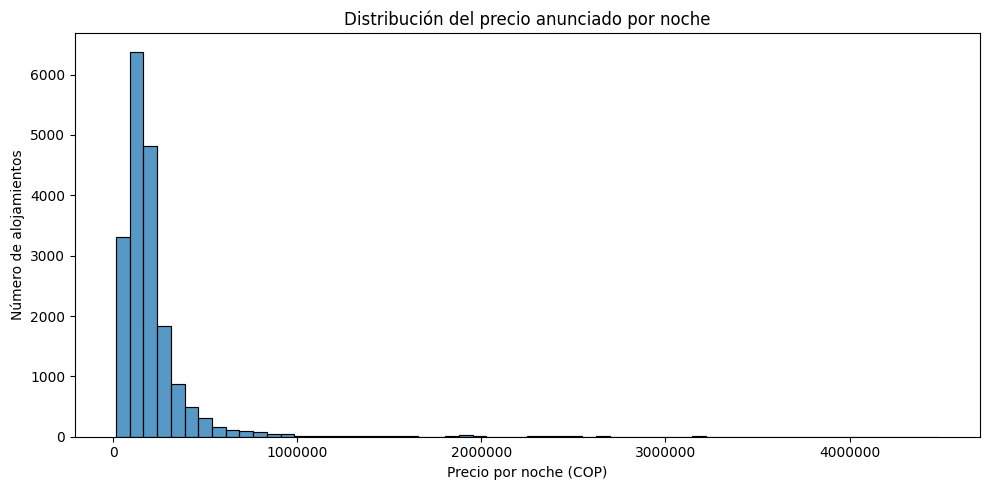

TIPOS DE ALOJAMIENTO MÁS FRECUENTES


,Cantidad
Tipo de alojamiento,
Entire home/apt,13626
Private room,4987
Shared room,119
Hotel room,27


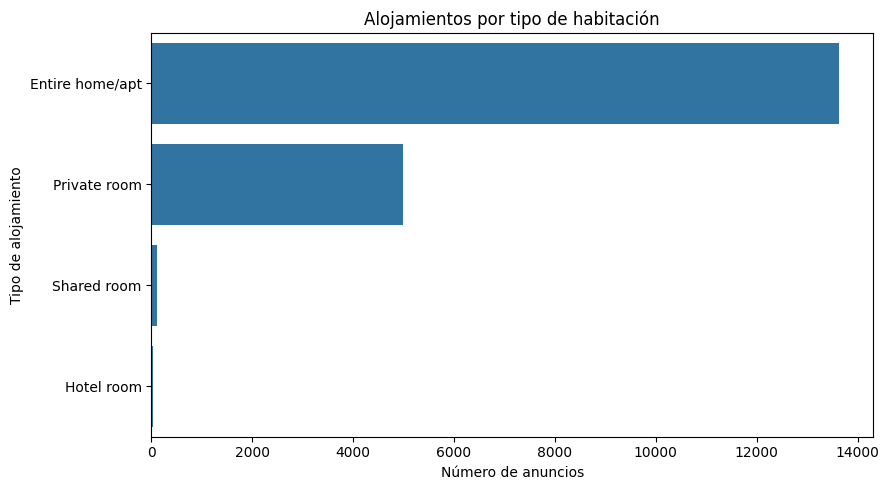

LOCALIDADES CON MÁS ANUNCIOS


,Cantidad de anuncios
Localidad,
Chapinero,4920
Usaquen,3401
Teusaquillo,2790
Santa Fe,1423
Engativa,1227
Suba,1199
Barrios Unidos,1033
Fontibon,994
Candelaria,726


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Estadísticas descriptivas del precio
print("ESTADÍSTICAS DEL PRECIO POR NOCHE (COP)")
display(
    listings_model["price_numeric"]
    .describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame()
    .round(0)
)

# 2. Distribución de precios
plt.figure(figsize=(10, 5))
sns.histplot(
    data=listings_model,
    x="price_numeric",
    bins=60
)
plt.title("Distribución del precio anunciado por noche")
plt.xlabel("Precio por noche (COP)")
plt.ylabel("Número de alojamientos")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

# 3. Tipos de alojamiento más frecuentes
print("TIPOS DE ALOJAMIENTO MÁS FRECUENTES")
display(
    listings_model["room_type"]
    .value_counts()
    .rename_axis("Tipo de alojamiento")
    .to_frame("Cantidad")
)

plt.figure(figsize=(9, 5))
sns.countplot(
    data=listings_model,
    y="room_type",
    order=listings_model["room_type"].value_counts().index
)
plt.title("Alojamientos por tipo de habitación")
plt.xlabel("Número de anuncios")
plt.ylabel("Tipo de alojamiento")
plt.tight_layout()
plt.show()

# 4. Número de anuncios por localidad
print("LOCALIDADES CON MÁS ANUNCIOS")
display(
    listings_model["neighbourhood_cleansed"]
    .value_counts()
    .head(20)
    .rename_axis("Localidad")
    .to_frame("Cantidad de anuncios")
)


PRECIOS POR LOCALIDAD


,cantidad,precio_mediano,precio_promedio
neighbourhood_cleansed,,,
Chapinero,4920,196000.0,274650.0
Usaquen,3401,193166.0,249883.0
Santa Fe,1423,149388.0,183704.0
Barrios Unidos,1033,147799.0,168431.0
Teusaquillo,2790,139629.0,166658.0
Fontibon,994,137000.0,162507.0
Candelaria,726,131040.0,149577.0
Suba,1199,130500.0,179938.0
Puente Aranda,231,130000.0,154314.0


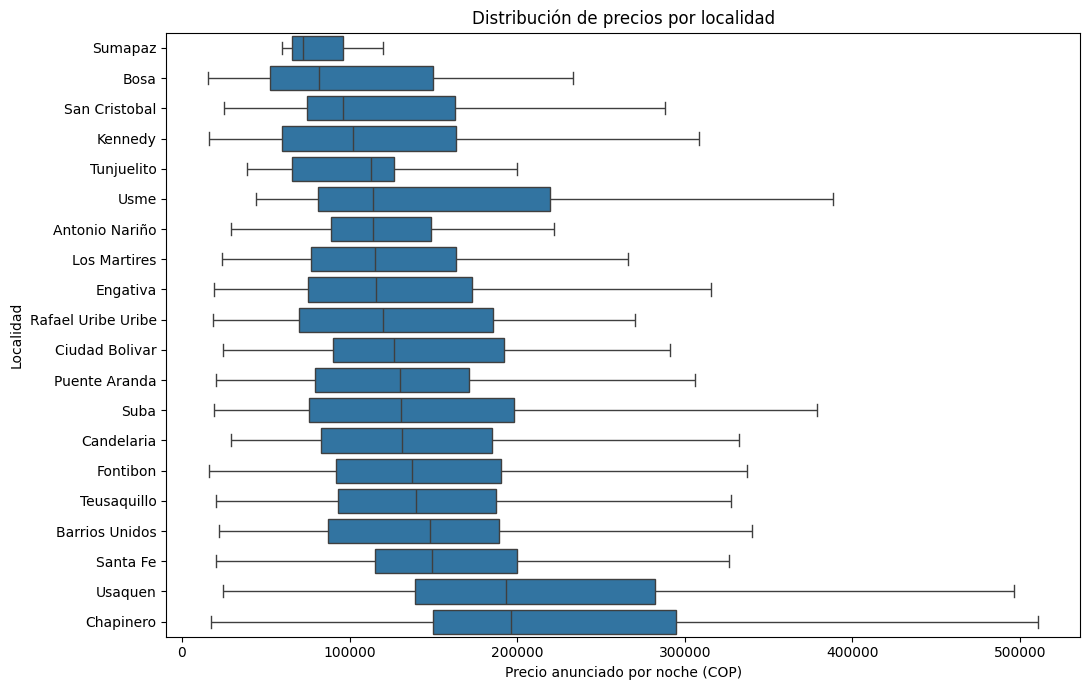

PRECIOS POR TIPO DE ALOJAMIENTO


,cantidad,precio_mediano,precio_promedio
room_type,,,
Hotel room,27,195000.0,198869.0
Entire home/apt,13626,181064.0,241604.0
Private room,4987,90000.0,122232.0
Shared room,119,40000.0,57476.0


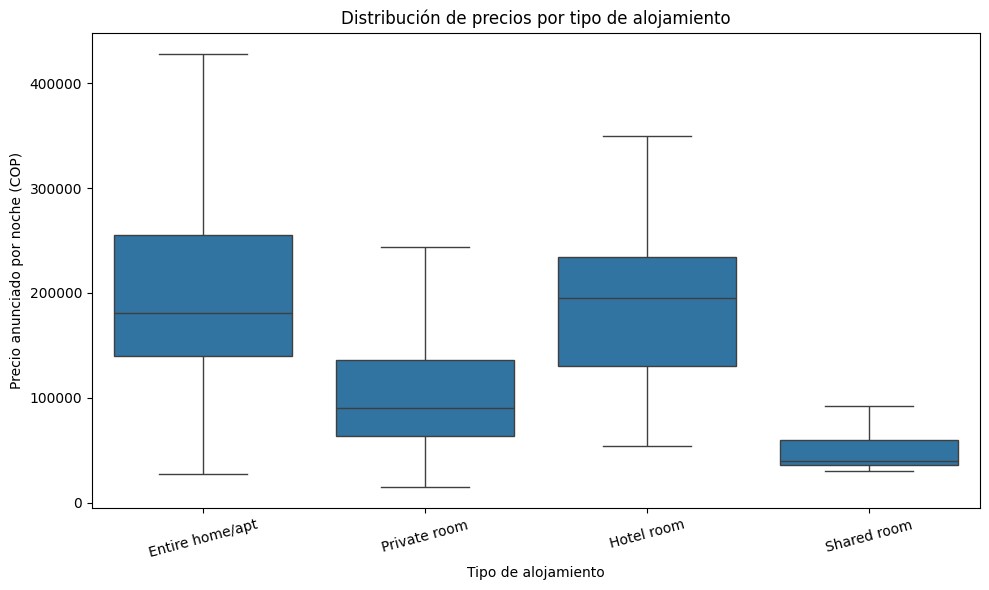

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tabla 1: precios por localidad
resumen_localidad = (
    listings_model
    .groupby("neighbourhood_cleansed")["price_numeric"]
    .agg(
        cantidad="count",
        precio_mediano="median",
        precio_promedio="mean"
    )
    .sort_values("precio_mediano", ascending=False)
)

resumen_localidad[
    ["precio_mediano", "precio_promedio"]
] = resumen_localidad[
    ["precio_mediano", "precio_promedio"]
].round(0)

print("PRECIOS POR LOCALIDAD")
display(resumen_localidad)

# Gráfico 1: mediana por localidad
plt.figure(figsize=(11, 7))
orden_localidades = (
    listings_model.groupby("neighbourhood_cleansed")["price_numeric"]
    .median()
    .sort_values()
    .index
)

sns.boxplot(
    data=listings_model,
    y="neighbourhood_cleansed",
    x="price_numeric",
    order=orden_localidades,
    showfliers=False
)
plt.title("Distribución de precios por localidad")
plt.xlabel("Precio anunciado por noche (COP)")
plt.ylabel("Localidad")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

# Tabla 2: precios según tipo de alojamiento
resumen_tipo = (
    listings_model
    .groupby("room_type")["price_numeric"]
    .agg(
        cantidad="count",
        precio_mediano="median",
        precio_promedio="mean"
    )
    .sort_values("precio_mediano", ascending=False)
)

resumen_tipo[
    ["precio_mediano", "precio_promedio"]
] = resumen_tipo[
    ["precio_mediano", "precio_promedio"]
].round(0)

print("PRECIOS POR TIPO DE ALOJAMIENTO")
display(resumen_tipo)

# Gráfico 2: comparación de precios por tipo
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=listings_model,
    x="room_type",
    y="price_numeric",
    showfliers=False
)
plt.title("Distribución de precios por tipo de alojamiento")
plt.xlabel("Tipo de alojamiento")
plt.ylabel("Precio anunciado por noche (COP)")
plt.ticklabel_format(style="plain", axis="y")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


PRECIO SEGÚN CAPACIDAD


,cantidad,precio_mediano,precio_promedio
accommodates,,,
1,1559,65848.0,82768.0
2,8325,143602.0,168662.0
3,3117,173000.0,204419.0
4,3158,195000.0,240381.0
5,958,247221.0,284863.0
6,813,297287.0,368125.0
7,154,310240.0,357759.0
8,240,360315.0,449889.0
9,45,300000.0,348044.0


PRECIO SEGÚN NÚMERO DE HABITACIONES


,cantidad,precio_mediano,precio_promedio
bedrooms,,,
0.0,500,126051.0,132451.0
1.0,13646,149673.0,174305.0
2.0,2975,216485.0,267053.0
3.0,1099,280961.0,355846.0
4.0,256,425356.0,531884.0
5.0,81,545944.0,658267.0
6.0,42,498056.0,487851.0
7.0,24,620181.0,642901.0
8.0,15,180000.0,633527.0


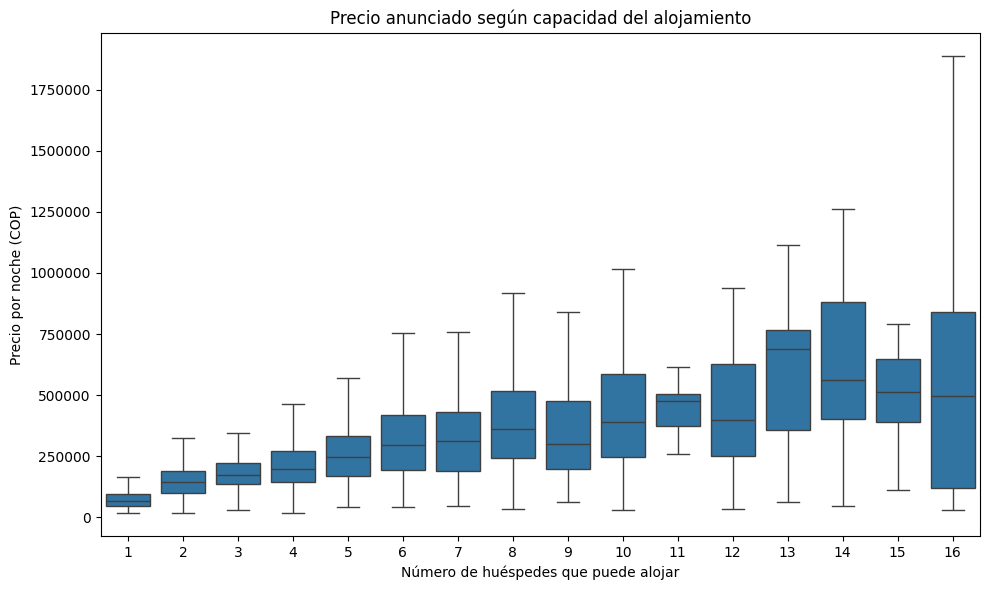

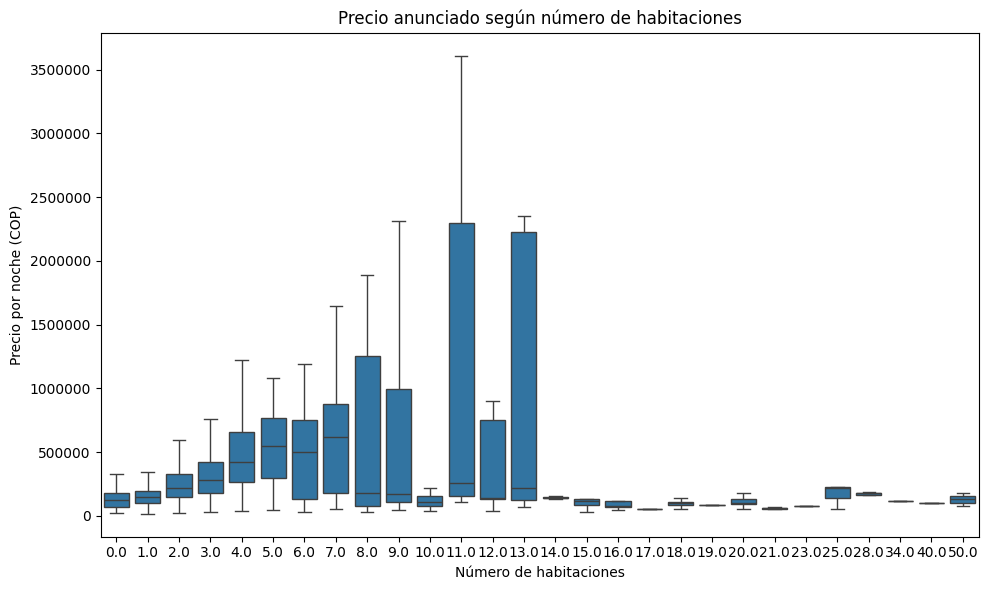

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Resumen de precio según capacidad
resumen_capacidad = (
    listings_model
    .groupby("accommodates")["price_numeric"]
    .agg(
        cantidad="count",
        precio_mediano="median",
        precio_promedio="mean"
    )
    .round(0)
)

print("PRECIO SEGÚN CAPACIDAD")
display(resumen_capacidad)

# 2. Precio según número de habitaciones
resumen_habitaciones = (
    listings_model
    .dropna(subset=["bedrooms"])
    .groupby("bedrooms")["price_numeric"]
    .agg(
        cantidad="count",
        precio_mediano="median",
        precio_promedio="mean"
    )
    .round(0)
)

print("PRECIO SEGÚN NÚMERO DE HABITACIONES")
display(resumen_habitaciones)

# 3. Gráfico: capacidad y precio
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=listings_model,
    x="accommodates",
    y="price_numeric",
    showfliers=False
)
plt.title("Precio anunciado según capacidad del alojamiento")
plt.xlabel("Número de huéspedes que puede alojar")
plt.ylabel("Precio por noche (COP)")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

# 4. Relación entre precio y habitaciones
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=listings_model.dropna(subset=["bedrooms"]),
    x="bedrooms",
    y="price_numeric",
    showfliers=False
)
plt.title("Precio anunciado según número de habitaciones")
plt.xlabel("Número de habitaciones")
plt.ylabel("Precio por noche (COP)")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()


Los alojamientos que pueden recibir más huéspedes tienden a presentar precios medianos más altos. Sin embargo, la relación no es perfectamente creciente: algunas capacidades presentan mucha dispersión y otras tienen pocos registros.


Importante: el gráfico muestra una asociación descriptiva, no demuestra causalidad.

In [ ]:

# Revisar cantidad de observaciones por capacidad
print("CANTIDAD DE ALOJAMIENTOS POR CAPACIDAD")
display(
    listings_model["accommodates"]
    .value_counts()
    .sort_index()
    .rename_axis("capacidad")
    .to_frame("cantidad")
)

# Revisar cantidad de observaciones por habitaciones
print("CANTIDAD DE ALOJAMIENTOS POR HABITACIONES")
display(
    listings_model["bedrooms"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("habitaciones")
    .to_frame("cantidad")
)

# Identificar categorías con pocas observaciones
print("CAPACIDADES CON MENOS DE 30 ALOJAMIENTOS")
display(
    listings_model["accommodates"]
    .value_counts()
    .loc[lambda x: x < 30]
    .sort_index()
    .rename_axis("capacidad")
    .to_frame("cantidad")
)

print("CATEGORÍAS DE HABITACIONES CON MENOS DE 30 ALOJAMIENTOS")
display(
    listings_model["bedrooms"]
    .value_counts()
    .loc[lambda x: x < 30]
    .sort_index()
    .rename_axis("habitaciones")
    .to_frame("cantidad")
)


CANTIDAD DE ALOJAMIENTOS POR CAPACIDAD


,cantidad
capacidad,
1,1559
2,8325
3,3117
4,3158
5,958
6,813
7,154
8,240
9,45


CANTIDAD DE ALOJAMIENTOS POR HABITACIONES


,cantidad
habitaciones,
0.0,500
1.0,13646
2.0,2975
3.0,1099
4.0,256
5.0,81
6.0,42
7.0,24
8.0,15


CAPACIDADES CON MENOS DE 30 ALOJAMIENTOS


,cantidad
capacidad,
11,18
13,13
15,18


CATEGORÍAS DE HABITACIONES CON MENOS DE 30 ALOJAMIENTOS


,cantidad
habitaciones,
7.0,24
8.0,15
9.0,11
10.0,28
11.0,9
12.0,10
13.0,5
14.0,2
15.0,5


In [ ]:

# Inspeccionar alojamientos con 10 o más habitaciones
columnas_revision = [
    "name",
    "property_type",
    "room_type",
    "accommodates",
    "bedrooms",
    "beds",
    "bathrooms_text",
    "price_numeric",
    "neighbourhood_cleansed"
]

columnas_revision = [
    c for c in columnas_revision
    if c in listings_model.columns
]

print("ALOJAMIENTOS CON 10 O MÁS HABITACIONES")

display(
    listings_model.loc[
        listings_model["bedrooms"] >= 10,
        columnas_revision
    ]
    .sort_values("bedrooms", ascending=False)
    .head(30)
)

print("ALOJAMIENTOS CON CERO HABITACIONES")

display(
    listings_model.loc[
        listings_model["bedrooms"] == 0,
        columnas_revision
    ].head(20)
)


ALOJAMIENTOS CON 10 O MÁS HABITACIONES


,name,property_type,room_type,accommodates,bedrooms,beds,bathrooms_text,price_numeric,neighbourhood_cleansed
814,Cómoda habitación. Dos camas Sencillas. Desayuno,Private room in home,Private room,16,50.0,40.0,0 shared baths,77843.0,Teusaquillo
8158,Habitacion individual Hotel Corferias,Room in hotel,Private room,1,50.0,50.0,50 baths,181000.0,Teusaquillo
8397,Hospedaje BusPlus+,Room in hotel,Private room,16,40.0,40.0,20 baths,100000.0,Puente Aranda
11695,Cama de Hotel cerca a corferias,Room in hotel,Private room,16,34.0,50.0,1 private bath,119648.0,Teusaquillo
13180,"Sencilla Superior, Hotel Abitare 57 Chapinero",Room in hotel,Private room,1,28.0,1.0,28 baths,136659.6,Chapinero
13818,"Doble Superior, Hotel Abitare 57 Chapinero",Room in hotel,Private room,2,28.0,1.0,6 baths,179628.0,Chapinero
13819,"Doble Estandar, Hotel Abitare 57 Chapinero",Room in hotel,Private room,2,28.0,1.0,6 baths,174678.9,Chapinero
13821,"Triple Superior, Hotel Abitare 57 Chapinero",Room in hotel,Private room,3,28.0,1.0,6 baths,185840.0,Chapinero
14546,Hotel Capsula Bogota 2-2 personas,Private room in home,Private room,2,25.0,1.0,5 shared baths,52671.0,Barrios Unidos
3331,Apartamento de 2 Habitaciones cerca al aeropuerto,Entire serviced apartment,Entire home/apt,4,25.0,48.0,40 baths,220000.0,Fontibon


ALOJAMIENTOS CON CERO HABITACIONES


,name,property_type,room_type,accommodates,bedrooms,beds,bathrooms_text,price_numeric,neighbourhood_cleansed
15,Excellent location. Cozy studio,Entire guesthouse,Entire home/apt,2,0.0,1.0,1 bath,124739.5,Suba
22,Luxurious - Close to everything WTC PARK 93,Entire loft,Entire home/apt,2,0.0,1.0,1.5 baths,183123.67,Chapinero
81,Bright Studio in Downtown Bogotá!,Entire rental unit,Entire home/apt,3,0.0,2.0,1 bath,121443.52,Santa Fe
189,apartaestudio palermo cll 44,Entire rental unit,Entire home/apt,1,0.0,1.0,1 bath,52281.88,Rafael Uribe Uribe
207,Studio Apartment in La Candelaria,Entire rental unit,Entire home/apt,4,0.0,2.0,1 bath,115506.0,Candelaria
261,Cosy Studio Apt with Terrace in the best locat...,Entire rental unit,Entire home/apt,2,0.0,1.0,1 bath,190607.14,Chapinero
282,"Studio Historical Center La Candelaria, Bogotá",Entire rental unit,Entire home/apt,2,0.0,1.0,1 bath,115256.0,Candelaria
287,APARTAMENTO 1-4 PERSONAS CANDELARIA,Entire rental unit,Entire home/apt,4,0.0,2.0,1 bath,74112.12,Puente Aranda
304,"Lego Apartment, work from here 200 Mb internet",Entire loft,Entire home/apt,2,0.0,1.0,1 bath,126132.47,Santa Fe
367,2 habitaciones Luxury,Entire condo,Entire home/apt,4,0.0,1.0,2.5 baths,681161.0,Chapinero


In [ ]:

import pandas as pd

# Crear una copia para auditar sin modificar la base original
auditoria = listings_model.copy()

# Identificar posibles inconsistencias
auditoria["habitaciones_extremas"] = (
    auditoria["bedrooms"] >= 10
)

auditoria["habitaciones_altas_baja_capacidad"] = (
    (auditoria["bedrooms"] >= 10) &
    (auditoria["accommodates"] <= 4)
)

# Mostrar cantidades
print("ALOJAMIENTOS CON 10 O MÁS HABITACIONES:",
      auditoria["habitaciones_extremas"].sum())

print("CON 10 O MÁS HABITACIONES Y CAPACIDAD DE 4 O MENOS:",
      auditoria["habitaciones_altas_baja_capacidad"].sum())

# Revisar el tipo de propiedad de esos registros
print("\nTIPOS DE PROPIEDAD EN LOS CASOS SOSPECHOSOS")

display(
    auditoria.loc[
        auditoria["habitaciones_altas_baja_capacidad"]
    ]
    .groupby("property_type")
    .size()
    .sort_values(ascending=False)
    .rename("cantidad")
    .to_frame()
)

# Revisar los casos con cero habitaciones
print("\nTIPO DE PROPIEDAD PARA ALOJAMIENTOS CON CERO HABITACIONES")

display(
    auditoria.loc[auditoria["bedrooms"] == 0]
    .groupby(["property_type", "room_type"])
    .size()
    .sort_values(ascending=False)
    .head(15)
    .rename("cantidad")
    .to_frame()
)


ALOJAMIENTOS CON 10 O MÁS HABITACIONES: 104
CON 10 O MÁS HABITACIONES Y CAPACIDAD DE 4 O MENOS: 50

TIPOS DE PROPIEDAD EN LOS CASOS SOSPECHOSOS


,cantidad
property_type,
Room in hotel,32
Private room in home,5
Private room in rental unit,4
Entire rental unit,2
Private room in bed and breakfast,2
Entire serviced apartment,1
Private room in hostel,1
Private room in guesthouse,1
Room in boutique hotel,1



TIPO DE PROPIEDAD PARA ALOJAMIENTOS CON CERO HABITACIONES


,,cantidad
property_type,room_type,
Entire rental unit,Entire home/apt,215
Entire loft,Entire home/apt,64
Private room in rental unit,Private room,48
Shared room in hotel,Shared room,38
Private room in home,Private room,36
Entire condo,Entire home/apt,18
Entire serviced apartment,Entire home/apt,17
Private room in condo,Private room,12
Shared room in home,Shared room,8


In [ ]:

# Crear una base de trabajo sin modificar listings_model
listings_preparacion = listings_model.copy()

# Preservar la variable original
listings_preparacion["bedrooms_original"] = (
    listings_preparacion["bedrooms"]
)

# Marcar casos que requieren revisión
listings_preparacion["bedrooms_sospechoso"] = (
    (listings_preparacion["bedrooms"] >= 10) &
    (listings_preparacion["accommodates"] <= 4)
)

# Variable corregida para el modelado
listings_preparacion["bedrooms_model"] = (
    listings_preparacion["bedrooms"]
)

listings_preparacion.loc[
    listings_preparacion["bedrooms_sospechoso"],
    "bedrooms_model"
] = float("nan")

print("Registros originales:", len(listings_preparacion))
print(
    "Habitaciones marcadas como sospechosas:",
    listings_preparacion["bedrooms_sospechoso"].sum()
)
print(
    "Faltantes en la variable de habitaciones para modelar:",
    listings_preparacion["bedrooms_model"].isna().sum()
)

display(
    listings_preparacion[
        ["bedrooms_original", "bedrooms_model",
         "bedrooms_sospechoso"]
    ].head(10)
)


Registros originales: 18759
Habitaciones marcadas como sospechosas: 50
Faltantes en la variable de habitaciones para modelar: 56


,bedrooms_original,bedrooms_model,bedrooms_sospechoso
0,2.0,2.0,False
1,1.0,1.0,False
2,1.0,1.0,False
3,1.0,1.0,False
4,1.0,1.0,False
5,1.0,1.0,False
6,2.0,2.0,False
7,1.0,1.0,False
8,3.0,3.0,False
9,1.0,1.0,False


In [ ]:

# Variables candidatas para predecir el precio
variables_modelo = [
    "price_numeric",
    "room_type",
    "property_type",
    "neighbourhood_cleansed",
    "accommodates",
    "bedrooms_model",
    "beds",
    "bathrooms_text",
    "minimum_nights",
    "number_of_reviews",
    "review_scores_rating"
]

# Conservar las columnas que existen en la base
variables_modelo = [
    c for c in variables_modelo
    if c in listings_preparacion.columns
]

base_revision = listings_preparacion[variables_modelo].copy()

# Auditoría de faltantes y tipos
resumen_modelo = pd.DataFrame({
    "tipo": base_revision.dtypes.astype(str),
    "faltantes": base_revision.isna().sum(),
    "porcentaje_faltantes": (
        base_revision.isna().mean() * 100
    ).round(2),
    "valores_unicos": base_revision.nunique()
})

display(resumen_modelo)


,tipo,faltantes,porcentaje_faltantes,valores_unicos
price_numeric,Float64,0,0.00,10592
room_type,object,0,0.00,4
property_type,object,0,0.00,70
neighbourhood_cleansed,object,0,0.00,20
accommodates,int64,0,0.00,16
bedrooms_model,float64,56,0.30,25
beds,float64,221,1.18,38
bathrooms_text,object,28,0.15,65
minimum_nights,float64,7,0.04,41
number_of_reviews,int64,0,0.00,377


In [ ]:

import pandas as pd

# Copia de trabajo
listings_preparacion["bathrooms_original"] = (
    listings_preparacion["bathrooms_text"]
)

# Extraer el primer número del texto, incluidos decimales
listings_preparacion["bathrooms_model"] = pd.to_numeric(
    listings_preparacion["bathrooms_text"]
    .astype("string")
    .str.extract(r"(\d+(?:\.\d+)?)", expand=False),
    errors="coerce"
)

print("Ejemplos de conversión:")
display(
    listings_preparacion[
        ["bathrooms_original", "bathrooms_model"]
    ].drop_duplicates().head(20)
)

print("\nResumen de baños:")
display(
    listings_preparacion["bathrooms_model"]
    .describe()
    .to_frame()
    .round(2)
)

print(
    "\nValores faltantes en baños:",
    listings_preparacion["bathrooms_model"].isna().sum()
)


Ejemplos de conversión:


,bathrooms_original,bathrooms_model
0,2.5 baths,2.5
1,0 shared baths,0.0
2,1 bath,1.0
3,2 baths,2.0
4,1 private bath,1.0
6,1 shared bath,1.0
8,3.5 baths,3.5
12,6 baths,6.0
22,1.5 baths,1.5
28,3 baths,3.0



Resumen de baños:


,bathrooms_model
count,18638.0
mean,1.41
std,1.36
min,0.0
25%,1.0
50%,1.0
75%,1.5
max,50.0



Valores faltantes en baños: 121


In [ ]:

import pandas as pd
import numpy as np

texto_banos = (
    listings_preparacion["bathrooms_original"]
    .astype("string")
    .str.lower()
    .str.strip()
)

# Reextraer los valores numéricos
banos_corregidos = pd.to_numeric(
    texto_banos.str.extract(
        r"(\d+(?:\.\d+)?)",
        expand=False
    ),
    errors="coerce"
)

# Casos expresados en palabras
banos_corregidos.loc[
    texto_banos.str.contains("half-bath", na=False)
] = 0.5

banos_corregidos.loc[
    texto_banos.str.contains("no bathroom", na=False)
] = 0.0

# Guardar la variable numérica corregida
listings_preparacion["bathrooms_model"] = banos_corregidos

print("Resumen de baños corregido:")
display(
    listings_preparacion["bathrooms_model"]
    .describe()
    .to_frame()
    .round(2)
)

print("\nValores de texto que continúan sin convertirse:")
display(
    listings_preparacion.loc[
        listings_preparacion["bathrooms_model"].isna(),
        "bathrooms_original"
    ]
    .value_counts(dropna=False)
    .head(20)
    .to_frame("cantidad")
)

print(
    "\nRegistros con 10 o más baños:",
    (listings_preparacion["bathrooms_model"] >= 10).sum()
)


Resumen de baños corregido:


,bathrooms_model
count,18731.0
mean,1.4
std,1.36
min,0.0
25%,1.0
50%,1.0
75%,1.5
max,50.0



Valores de texto que continúan sin convertirse:


,cantidad
bathrooms_original,
NaN,28



Registros con 10 o más baños: 102


In [ ]:

# Revisar frecuencia de tipos de propiedad
frecuencia_propiedad = (
    listings_preparacion["property_type"]
    .value_counts(dropna=False)
)

print("Cantidad de tipos de propiedad:",
      listings_preparacion["property_type"].nunique())

print("\nCategorías con menos de 30 registros:")
display(
    frecuencia_propiedad[frecuencia_propiedad < 30]
    .rename_axis("property_type")
    .to_frame("cantidad")
)

print("\nResumen de variables categóricas:")
for variable in [
    "room_type",
    "property_type",
    "neighbourhood_cleansed"
]:
    print(
        f"{variable}:",
        listings_preparacion[variable].nunique(),
        "categorías"
    )

# Comprobar tamaño y faltantes de las variables candidatas
variables_finales = [
    "price_numeric",
    "room_type",
    "property_type",
    "neighbourhood_cleansed",
    "accommodates",
    "bedrooms_model",
    "beds",
    "bathrooms_model",
    "minimum_nights",
    "number_of_reviews"
]

base_modelo = listings_preparacion[variables_finales].copy()

print("\nDimensiones de la base candidata:", base_modelo.shape)
display(
    pd.DataFrame({
        "faltantes": base_modelo.isna().sum(),
        "porcentaje": (
            base_modelo.isna().mean() * 100
        ).round(2)
    })
)


Cantidad de tipos de propiedad: 70

Categorías con menos de 30 registros:


,cantidad
property_type,
Private room in townhouse,29
Shared room in home,24
Entire guest suite,24
Entire cabin,23
Private room,15
Private room in vacation home,14
Tiny home,14
Shared room in guesthouse,13
Entire townhouse,12



Resumen de variables categóricas:
room_type: 4 categorías
property_type: 70 categorías
neighbourhood_cleansed: 20 categorías

Dimensiones de la base candidata: (18759, 10)


,faltantes,porcentaje
price_numeric,0,0.00
room_type,0,0.00
property_type,0,0.00
neighbourhood_cleansed,0,0.00
accommodates,0,0.00
bedrooms_model,56,0.30
beds,221,1.18
bathrooms_model,28,0.15
minimum_nights,7,0.04
number_of_reviews,0,0.00


In [ ]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Variables predictoras y objetivo
X = base_modelo.drop(columns=["price_numeric"]).copy()
y = base_modelo["price_numeric"].astype(float).copy()

# División antes de aprender cualquier transformación
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# Columnas numéricas y categóricas
numericas = [
    "accommodates",
    "bedrooms_model",
    "beds",
    "bathrooms_model",
    "minimum_nights",
    "number_of_reviews"
]

categoricas = [
    "room_type",
    "property_type",
    "neighbourhood_cleansed"
]

# Preprocesamiento numérico
preprocesamiento_numerico = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])

# Preprocesamiento categórico:
# las categorías con menos de 30 casos en entrenamiento
# se agrupan en "Other".
def agrupar_categorias_raras(datos):
    datos = datos.copy()

    for columna in categoricas:
        frecuencias = datos[columna].value_counts()
        categorias_comunes = frecuencias[
            frecuencias >= 30
        ].index

        datos[columna] = datos[columna].where(
            datos[columna].isin(categorias_comunes),
            "Other"
        )

    return datos

# Aprender agrupación solo en entrenamiento
X_train_agrupado = agrupar_categorias_raras(X_train)

frecuencias_entrenamiento = {
    columna: X_train[columna].value_counts()
    for columna in categoricas
}

def transformar_categorias(datos):
    datos = datos.copy()

    for columna in categoricas:
        comunes = frecuencias_entrenamiento[columna]
        categorias_comunes = comunes[
            comunes >= 30
        ].index

        datos[columna] = datos[columna].where(
            datos[columna].isin(categorias_comunes),
            "Other"
        )

    return datos

X_train_agrupado = transformar_categorias(X_train)
X_test_agrupado = transformar_categorias(X_test)

preprocesamiento_categorico = Pipeline([
    ("imputacion", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("codificacion", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocesador = ColumnTransformer([
    ("numericas", preprocesamiento_numerico, numericas),
    ("categoricas", preprocesamiento_categorico, categoricas)
])

modelo_base = Pipeline([
    ("preprocesamiento", preprocesador),
    ("regresion", Ridge(alpha=1.0))
])

# Entrenar y evaluar
modelo_base.fit(X_train_agrupado, y_train)

predicciones = modelo_base.predict(X_test_agrupado)

mae = mean_absolute_error(y_test, predicciones)
rmse = np.sqrt(mean_squared_error(y_test, predicciones))
r2 = r2_score(y_test, predicciones)

print("RESULTADOS DEL MODELO BASE")
print(f"MAE:  ${mae:,.0f} COP")
print(f"RMSE: ${rmse:,.0f} COP")
print(f"R²:   {r2:.4f}")

print("\nTamaño entrenamiento:", len(X_train))
print("Tamaño prueba:", len(X_test))


RESULTADOS DEL MODELO BASE
MAE:  $88,375 COP
RMSE: $205,717 COP
R²:   0.2584

Tamaño entrenamiento: 15007
Tamaño prueba: 3752


MAE de $88.375: en promedio, la predicción se desvía del precio anunciado real en unos $88.375 COP por noche.



RMSE de $205.717: los errores grandes están elevando el indicador. La diferencia considerable entre RMSE y MAE sugiere que algunos alojamientos generan errores de predicción especialmente altos.



R² de 0,2584: el modelo explica aproximadamente el 25,84% de la variación de los precios en los datos de prueba. Hay información útil en las variables, pero todavía queda bastante variabilidad sin explicar.

In [ ]:

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# 1. Modelo de referencia: predecir siempre la mediana
modelo_ingenuo = DummyRegressor(strategy="median")
modelo_ingenuo.fit(X_train_agrupado, y_train)

pred_dummy = modelo_ingenuo.predict(X_test_agrupado)

# 2. Red neuronal sencilla
modelo_red = Pipeline([
    ("preprocesamiento", clone(preprocesador)),
    ("red", MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=0.01,
        learning_rate_init=0.001,
        max_iter=200,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=15,
        random_state=42
    ))
])

modelo_red.fit(X_train_agrupado, y_train)
pred_red = modelo_red.predict(X_test_agrupado)

# 3. Comparación en las mismas observaciones
def calcular_metricas(nombre, reales, predichos):
    return {
        "Modelo": nombre,
        "MAE_COP": mean_absolute_error(reales, predichos),
        "RMSE_COP": np.sqrt(
            mean_squared_error(reales, predichos)
        ),
        "R2": r2_score(reales, predichos)
    }

comparacion = pd.DataFrame([
    calcular_metricas("Referencia: mediana", y_test, pred_dummy),
    calcular_metricas("Ridge", y_test, predicciones),
    calcular_metricas("Red neuronal", y_test, pred_red)
])

display(comparacion.round(4))

print("Iteraciones realizadas por la red:",
      modelo_red.named_steps["red"].n_iter_)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


,Modelo,MAE_COP,RMSE_COP,R2
0,Referencia: mediana,106627.7176,243844.7690,-0.0420
1,Ridge,88374.9279,205717.2660,0.2584
2,Red neuronal,86872.6600,205723.8308,0.2583


Iteraciones realizadas por la red: 200


In [ ]:

from sklearn.base import clone
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Red neuronal con transformación logarítmica del precio
red_log = Pipeline([
    ("preprocesamiento", clone(preprocesador)),
    ("red", MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=0.01,
        learning_rate_init=0.001,
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=20,
        random_state=42
    ))
])

modelo_log = TransformedTargetRegressor(
    regressor=red_log,
    func=np.log1p,
    inverse_func=np.expm1
)

modelo_log.fit(X_train_agrupado, y_train)

pred_log = modelo_log.predict(X_test_agrupado)

# Comparación en pesos colombianos
resultados_log = {
    "Modelo": "Red neuronal con precio logarítmico",
    "MAE_COP": mean_absolute_error(y_test, pred_log),
    "RMSE_COP": np.sqrt(mean_squared_error(y_test, pred_log)),
    "R2": r2_score(y_test, pred_log)
}

comparacion_final = pd.concat([
    comparacion,
    pd.DataFrame([resultados_log])
], ignore_index=True)

display(comparacion_final.round(4))

red_entrenada = modelo_log.regressor_.named_steps["red"]
print("Iteraciones realizadas:", red_entrenada.n_iter_)
print("¿Convergió antes del límite?:", red_entrenada.n_iter_ < 500)


,Modelo,MAE_COP,RMSE_COP,R2
0,Referencia: mediana,106627.7176,243844.7690,-0.0420
1,Ridge,88374.9279,205717.2660,0.2584
2,Red neuronal,86872.6600,205723.8308,0.2583
3,Red neuronal con precio logarítmico,74740.3416,198514.4249,0.3094


Iteraciones realizadas: 77
¿Convergió antes del límite?: True


In [ ]:

# Evaluación del modelo por rangos de precio real
evaluacion = pd.DataFrame({
    "precio_real": y_test.to_numpy(),
    "precio_predicho": np.asarray(pred_log)
})

evaluacion["error_absoluto"] = (
    evaluacion["precio_real"] - evaluacion["precio_predicho"]
).abs()

evaluacion["rango_precio"] = pd.cut(
    evaluacion["precio_real"],
    bins=[0, 100_000, 200_000, 350_000, 500_000, np.inf],
    labels=[
        "Hasta $100.000",
        "$100.001–$200.000",
        "$200.001–$350.000",
        "$350.001–$500.000",
        "Más de $500.000"
    ],
    include_lowest=True
)

resumen_rangos = evaluacion.groupby(
    "rango_precio", observed=False
).agg(
    alojamientos=("precio_real", "size"),
    precio_real_mediano=("precio_real", "median"),
    precio_predicho_mediano=("precio_predicho", "median"),
    MAE=("error_absoluto", "mean")
).round(0)

display(resumen_rangos)


,alojamientos,precio_real_mediano,precio_predicho_mediano,MAE
rango_precio,,,,
Hasta $100.000,855,71400.0,88878.0,35466.0
$100.001–$200.000,1683,150000.0,167633.0,36665.0
$200.001–$350.000,831,245060.0,212256.0,62842.0
$350.001–$500.000,204,415887.0,285841.0,146616.0
Más de $500.000,179,731500.0,392281.0,593652.0


In [ ]:

evaluacion["error_firmado"] = (
    evaluacion["precio_predicho"] - evaluacion["precio_real"]
)

resumen_sesgo = evaluacion.groupby(
    "rango_precio", observed=False
).agg(
    alojamientos=("precio_real", "size"),
    precio_real_promedio=("precio_real", "mean"),
    precio_predicho_promedio=("precio_predicho", "mean"),
    error_firmado_promedio=("error_firmado", "mean"),
    MAE=("error_absoluto", "mean")
).round(0)

display(resumen_sesgo)


,alojamientos,precio_real_promedio,precio_predicho_promedio,error_firmado_promedio,MAE
rango_precio,,,,,
Hasta $100.000,855,69024.0,99116.0,30092.0,35466.0
$100.001–$200.000,1683,150661.0,169178.0,18517.0,36665.0
$200.001–$350.000,831,256099.0,233067.0,-23032.0,62842.0
$350.001–$500.000,204,419213.0,316386.0,-102827.0,146616.0
Más de $500.000,179,990819.0,464812.0,-526007.0,593652.0


In [ ]:

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

modelo_rf = Pipeline([
    ("preprocesamiento", clone(preprocesador)),
    ("bosque", RandomForestRegressor(
        n_estimators=150,
        max_depth=18,
        min_samples_leaf=5,
        max_features=0.8,
        n_jobs=-1,
        random_state=42
    ))
])

modelo_rf.fit(X_train_agrupado, y_train)

pred_rf = modelo_rf.predict(X_test_agrupado)

resultado_rf = {
    "Modelo": "Random Forest",
    "MAE_COP": mean_absolute_error(y_test, pred_rf),
    "RMSE_COP": np.sqrt(mean_squared_error(y_test, pred_rf)),
    "R2": r2_score(y_test, pred_rf)
}

comparacion_modelos = pd.concat([
    comparacion,
    pd.DataFrame([resultado_rf])
], ignore_index=True)

display(comparacion_modelos.round(4))


,Modelo,MAE_COP,RMSE_COP,R2
0,Referencia: mediana,106627.7176,243844.7690,-0.0420
1,Ridge,88374.9279,205717.2660,0.2584
2,Red neuronal,86872.6600,205723.8308,0.2583
3,Random Forest,77806.7323,193974.7213,0.3406


In [ ]:

evaluacion_rf = pd.DataFrame({
    "precio_real": y_test.to_numpy(),
    "precio_predicho": np.asarray(pred_rf)
})

evaluacion_rf["error_absoluto"] = (
    evaluacion_rf["precio_predicho"]
    - evaluacion_rf["precio_real"]
).abs()

evaluacion_rf["error_firmado"] = (
    evaluacion_rf["precio_predicho"]
    - evaluacion_rf["precio_real"]
)

evaluacion_rf["rango_precio"] = pd.cut(
    evaluacion_rf["precio_real"],
    bins=[0, 100_000, 200_000, 350_000, 500_000, np.inf],
    labels=[
        "Hasta $100.000",
        "$100.001–$200.000",
        "$200.001–$350.000",
        "$350.001–$500.000",
        "Más de $500.000"
    ],
    include_lowest=True
)

resumen_rf = evaluacion_rf.groupby(
    "rango_precio", observed=False
).agg(
    alojamientos=("precio_real", "size"),
    precio_real_promedio=("precio_real", "mean"),
    precio_predicho_promedio=("precio_predicho", "mean"),
    error_firmado_promedio=("error_firmado", "mean"),
    MAE=("error_absoluto", "mean")
).round(0)

display(resumen_rf)


,alojamientos,precio_real_promedio,precio_predicho_promedio,error_firmado_promedio,MAE
rango_precio,,,,,
Hasta $100.000,855,69024.0,109660.0,40637.0,42648.0
$100.001–$200.000,1683,150661.0,183899.0,33238.0,46135.0
$200.001–$350.000,831,256099.0,260859.0,4760.0,69554.0
$350.001–$500.000,204,419213.0,352595.0,-66617.0,131697.0
Más de $500.000,179,990819.0,515783.0,-475036.0,520425.0


In [ ]:

# Obtener nombres de las variables después del preprocesamiento
preprocesador_rf = modelo_rf.named_steps["preprocesamiento"]
bosque = modelo_rf.named_steps["bosque"]

nombres_variables = preprocesador_rf.get_feature_names_out()
importancias = bosque.feature_importances_

importancia_variables = pd.DataFrame({
    "variable": nombres_variables,
    "importancia": importancias
}).sort_values("importancia", ascending=False)

display(importancia_variables.head(20).round(4))


,variable,importancia
0,numericas__accommodates,0.2061
3,numericas__bathrooms_model,0.2037
5,numericas__number_of_reviews,0.1446
6,categoricas__room_type_Entire home/apt,0.0897
4,numericas__minimum_nights,0.0813
1,numericas__bedrooms_model,0.0644
35,categoricas__neighbourhood_cleansed_Chapinero,0.0490
2,numericas__beds,0.0459
48,categoricas__neighbourhood_cleansed_Usaquen,0.0232
8,categoricas__room_type_Private room,0.0157


In [ ]:

# Recuperar las características del conjunto de prueba
analisis_predicciones = X_test_agrupado.copy()
analisis_predicciones["precio_real"] = y_test.to_numpy()
analisis_predicciones["precio_predicho_rf"] = pred_rf

# Precio predicho por tipo de alojamiento
por_tipo = analisis_predicciones.groupby(
    "room_type", observed=False
).agg(
    alojamientos=("precio_real", "size"),
    precio_real_mediano=("precio_real", "median"),
    precio_predicho_mediano=("precio_predicho_rf", "median"),
    precio_predicho_promedio=("precio_predicho_rf", "mean")
).sort_values("precio_predicho_mediano", ascending=False).round(0)

print("Precio por tipo de alojamiento")
display(por_tipo)

# Precio predicho por capacidad
por_capacidad = analisis_predicciones.groupby(
    "accommodates", observed=False
).agg(
    alojamientos=("precio_real", "size"),
    precio_real_mediano=("precio_real", "median"),
    precio_predicho_mediano=("precio_predicho_rf", "median")
).sort_index().round(0)

print("Precio por capacidad")
display(por_capacidad)


Precio por tipo de alojamiento


,alojamientos,precio_real_mediano,precio_predicho_mediano,precio_predicho_promedio
room_type,,,,
Entire home/apt,2689,180903.0,199056.0,244605.0
Other,7,180000.0,150973.0,165811.0
Private room,1033,90000.0,103001.0,119329.0
Shared room,23,40000.0,74141.0,92223.0


Precio por capacidad


,alojamientos,precio_real_mediano,precio_predicho_mediano
accommodates,,,
1,325,62016.0,75179.0
2,1652,141718.0,158104.0
3,593,170072.0,186216.0
4,640,195281.0,208684.0
5,199,257171.0,252762.0
6,165,300000.0,318873.0
7,33,329680.0,322863.0
8,48,342576.0,409638.0
9,11,461133.0,499424.0


In [ ]:

from sklearn.base import clone
from sklearn.model_selection import KFold, cross_validate
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
import pandas as pd
import numpy as np

# Validación cruzada sobre el conjunto de entrenamiento
cv = KFold(n_splits=3, shuffle=True, random_state=42)

# Random Forest
rf_cv = Pipeline([
    ("preprocesamiento", clone(preprocesador)),
    ("bosque", RandomForestRegressor(
        n_estimators=150,
        max_depth=18,
        min_samples_leaf=5,
        max_features=0.8,
        n_jobs=-1,
        random_state=42
    ))
])

# Red neuronal con objetivo logarítmico
red_cv = Pipeline([
    ("preprocesamiento", clone(preprocesador)),
    ("red", MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=0.01,
        learning_rate_init=0.001,
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=20,
        random_state=42
    ))
])

red_log_cv = TransformedTargetRegressor(
    regressor=red_cv,
    func=np.log1p,
    inverse_func=np.expm1
)

modelos_cv = {
    "Random Forest": rf_cv,
    "Red neuronal logarítmica": red_log_cv
}

resultados_cv = []

for nombre, modelo in modelos_cv.items():
    scores = cross_validate(
        modelo,
        X_train_agrupado,
        y_train,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=1
    )

    resultados_cv.append({
        "Modelo": nombre,
        "MAE_promedio_COP": -scores["test_mae"].mean(),
        "MAE_desviacion_COP": scores["test_mae"].std(),
        "RMSE_promedio_COP": -scores["test_rmse"].mean(),
        "R2_promedio": scores["test_r2"].mean()
    })

display(pd.DataFrame(resultados_cv).round(3))


,Modelo,MAE_promedio_COP,MAE_desviacion_COP,RMSE_promedio_COP,R2_promedio
0,Random Forest,79861.560,2339.258,1.947264e+05,0.279
1,Red neuronal logarítmica,2506424.557,3443194.003,1.721233e+08,-1343353.663


In [ ]:

import joblib
from sklearn.base import clone
from pathlib import Path

# Agrupar categorías usando el criterio definido anteriormente
X_completo_agrupado = transformar_categorias(X)

# Entrenar la versión de producción con todos los datos disponibles
modelo_final = clone(modelo_rf)
modelo_final.fit(X_completo_agrupado, y)

# Guardar modelo y metadatos necesarios para reproducir
# la transformación de categorías en la aplicación
categorias_comunes = {
    columna: frecuencias_entrenamiento[columna]
        [frecuencias_entrenamiento[columna] >= 30]
        .index.tolist()
    for columna in categoricas
}

artefacto = {
    "modelo": modelo_final,
    "categorias_comunes": categorias_comunes,
    "variables_numericas": numericas,
    "variables_categoricas": categoricas,
    "variable_objetivo": "price_numeric",
    "unidad_objetivo": "COP por noche",
    "metricas_test": {
        "MAE_COP": 77806.73,
        "RMSE_COP": 193974.72,
        "R2": 0.3406
    }
}

Path("modelos").mkdir(exist_ok=True)
joblib.dump(artefacto, "modelos/modelo_precio_bogota.joblib")

print("Modelo exportado correctamente.")
print("Archivo: modelos/modelo_precio_bogota.joblib")
print("Registros usados para el ajuste final:", len(y))


Modelo exportado correctamente.
Archivo: modelos/modelo_precio_bogota.joblib
Registros usados para el ajuste final: 18759


## Conclusiones del análisis

El análisis de los anuncios de alojamientos de Airbnb en Bogotá evidencia diferencias de precios asociadas con las características físicas, el tipo de alojamiento y la ubicación. Entre las variables utilizadas por Random Forest, la capacidad del alojamiento y el número de baños presentaron las mayores importancias predictivas, con valores de 20,61 % y 20,37 %, respectivamente. El número de reseñas representó el 14,46 % de la importancia del modelo.

En la comparación de modelos, Random Forest obtuvo un MAE de aproximadamente $77.807 COP, un RMSE de $193.975 COP y un coeficiente de determinación de 0,3406 en el conjunto de prueba. En la validación cruzada de tres particiones, el MAE promedio fue de aproximadamente $79.862 COP y el R² promedio fue de 0,279. Estos resultados respaldan su selección como modelo principal provisional.

La evaluación por segmentos mostró que las predicciones presentan mayores dificultades en los alojamientos de precios elevados. En el segmento superior a $500.000 COP por noche, el modelo subestimó el precio promedio en aproximadamente $475.036 COP. Por ello, las estimaciones deben interpretarse con especial cautela en este segmento.

El modelo permite generar una referencia del precio anunciado a partir de las características de un alojamiento. Sin embargo, no estima directamente el precio óptimo, las reservas efectivas ni la rentabilidad real. Para evaluar escenarios económicos, será necesario incorporar supuestos de ocupación, costos operativos y otros parámetros proporcionados por el usuario.

### Limitaciones

- Los precios corresponden a anuncios y no necesariamente a ingresos efectivamente recibidos.
- La capacidad predictiva del modelo es limitada: un R² de 0,3406 indica que todavía existe una proporción importante de variabilidad que no explica.
- La importancia de las variables representa utilidad predictiva dentro del modelo, no causalidad.
- Los anuncios de precio elevado presentan errores mayores y requieren validación adicional.
- La rentabilidad del simulador dependerá de los supuestos introducidos por el usuario y no debe interpretarse como una garantía de resultados.

In [ ]:

import joblib
import pandas as pd
import numpy as np
from pathlib import Path

# 1. Comprobar que existe el archivo
ruta_modelo = Path("modelos/modelo_precio_bogota.joblib")

assert ruta_modelo.exists(), "No se encontró el archivo del modelo."

# 2. Cargar el modelo exportado
artefacto_cargado = joblib.load(ruta_modelo)
modelo_cargado = artefacto_cargado["modelo"]

# 3. Tomar un alojamiento de prueba
# Usamos las variables ya agrupadas como espera el modelo
ejemplo = X_test_agrupado.iloc[[0]].copy()

# 4. Generar la predicción
precio_estimado = modelo_cargado.predict(ejemplo)[0]

print("Archivo cargado correctamente.")
print("Número de variables recibidas:", ejemplo.shape[1])
print("Precio estimado por noche: ${:,.0f} COP".format(precio_estimado))

# 5. Verificar que la predicción sea válida
assert np.isfinite(precio_estimado), "La predicción no es un número válido."
assert precio_estimado > 0, "La predicción no es positiva."

print("Prueba de predicción superada.")


Archivo cargado correctamente.
Número de variables recibidas: 9
Precio estimado por noche: $316,001 COP
Prueba de predicción superada.


In [ ]:

from pathlib import Path

print("Archivos del proyecto:\n")

for ruta in sorted(Path(".").iterdir()):
    if ruta.is_file():
        tamano_mb = ruta.stat().st_size / (1024 * 1024)
        print(f"Archivo: {ruta} | {tamano_mb:.2f} MB")
    elif ruta.is_dir() and ruta.name != ".config":
        print(f"Carpeta: {ruta}/")
        for archivo in sorted(ruta.rglob("*")):
            if archivo.is_file():
                tamano_mb = archivo.stat().st_size / (1024 * 1024)
                print(f"  {archivo} | {tamano_mb:.2f} MB")


Archivos del proyecto:

Archivo: calendar.csv | 249.68 MB
Carpeta: drive/
  drive/MyDrive/807 - Contrato.docx | 0.80 MB
  drive/MyDrive/All_Beauty.jsonl | 311.48 MB
  drive/MyDrive/AxisHealth_ModeloFinanciero_CFO_v2.gsheet | 0.00 MB
  drive/MyDrive/C60_Rentals_Agosto2026_David_Murcia.gdoc | 0.00 MB
  drive/MyDrive/C60_Rentals_Agosto2026_David_Murcia.pdf | 0.14 MB
  drive/MyDrive/C60_Rentals_Septiembre2026_Andres_Baron (1).gdoc | 0.00 MB
  drive/MyDrive/C60_Rentals_Septiembre2026_Andres_Baron-2.docx | 0.11 MB
  drive/MyDrive/C60_Rentals_Septiembre2026_Andres_Baron.gdoc | 0.00 MB
  drive/MyDrive/CONFIRMACION EN LOS AMIGODEL 7 AL 10 JUN.pdf | 0.13 MB
  drive/MyDrive/CV_Maria_Fernanda_Gonzalez.pdf | 0.74 MB
  drive/MyDrive/Colab Notebooks/00_Validacion_Base_Amazon_Reviews.ipynb | 0.03 MB
  drive/MyDrive/Colab Notebooks/Amazon_Reviews_All_Beauty_Notebook_Limpio.ipynb | 0.04 MB
  drive/MyDrive/Colab Notebooks/Copia de Martes SIG TALLER_SQL.ipynb | 0.15 MB
  drive/MyDrive/Colab Notebooks/EXAM

In [ ]:

from pathlib import Path

raiz = Path(".")
git_dir = raiz / ".git"

print("¿Existe un repositorio Git?:", git_dir.exists())
print("\nArchivos principales del proyecto:")

for nombre in [
    "Proyecto_Analitica_Airbnb_Bogota.ipynb",
    "README.md",
    ".gitignore",
    "requirements.txt",
    "modelos/modelo_precio_bogota.joblib"
]:
    ruta = raiz / nombre
    print(f"{nombre}: {'Existe' if ruta.exists() else 'No encontrado'}")


¿Existe un repositorio Git?: False

Archivos principales del proyecto:
Proyecto_Analitica_Airbnb_Bogota.ipynb: No encontrado
README.md: No encontrado
.gitignore: No encontrado
requirements.txt: No encontrado
modelos/modelo_precio_bogota.joblib: Existe


In [ ]:

from google.colab import drive
from pathlib import Path
import shutil

# Conectar Google Drive si aún no está montado
drive.mount("/content/drive")

# Crear carpeta exclusiva del proyecto
proyecto = Path(
    "/content/drive/MyDrive/Proyecto_Airbnb_Bogota"
)

proyecto.mkdir(parents=True, exist_ok=True)

(proyecto / "modelos").mkdir(exist_ok=True)
(proyecto / "notebooks").mkdir(exist_ok=True)
(proyecto / "documentacion").mkdir(exist_ok=True)

# Copiar el modelo exportado a la carpeta del proyecto
origen_modelo = Path(
    "/content/modelos/modelo_precio_bogota.joblib"
)
destino_modelo = proyecto / "modelos" / "modelo_precio_bogota.joblib"

if origen_modelo.exists():
    shutil.copy2(origen_modelo, destino_modelo)
    print("Modelo copiado correctamente.")
else:
    print("No se encontró el modelo en la ruta de origen.")

print("\nCarpeta del proyecto:", proyecto)
print("Subcarpetas:", [p.name for p in proyecto.iterdir() if p.is_dir()])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Modelo copiado correctamente.

Carpeta del proyecto: /content/drive/MyDrive/Proyecto_Airbnb_Bogota
Subcarpetas: ['modelos', 'notebooks', 'documentacion']


In [ ]:

from pathlib import Path
import shutil

drive = Path("/content/drive/MyDrive")
carpeta_proyecto = drive / "Proyecto_Airbnb_Bogota"
carpeta_notebooks = carpeta_proyecto / "notebooks"

# Buscar notebooks con nombres relacionados con Airbnb
candidatos = [
    p for p in (drive / "Colab Notebooks").glob("*")
    if p.is_file()
    and p.suffix == ".ipynb"
    and "airbnb" in p.name.lower()
    and "bogota" in p.name.lower()
]

print("Notebooks candidatos encontrados:")
for i, archivo in enumerate(candidatos, start=1):
    print(f"{i}. {archivo.name}")

if len(candidatos) == 1:
    origen = candidatos[0]
    destino = carpeta_notebooks / "Proyecto_Analitica_Airbnb_Bogota.ipynb"

    if destino.exists():
        print("\nYa existe un notebook de destino. No se sobrescribió.")
    else:
        shutil.copy2(origen, destino)
        print("\nNotebook copiado:", destino)

elif len(candidatos) == 0:
    print("\nNo se encontró un candidato único. Revisaremos la ubicación.")

else:
    print("\nHay varios candidatos. Debemos elegir el correcto antes de copiar.")


Notebooks candidatos encontrados:

No se encontró un candidato único. Revisaremos la ubicación.


In [ ]:

from pathlib import Path

drive = Path("/content/drive/MyDrive")

print("Buscando notebooks y archivos relacionados...\n")

coincidencias = []

for archivo in drive.rglob("*"):
    if not archivo.is_file():
        continue

    nombre = archivo.name.lower()

    if (
        "airbnb" in nombre
        or "bogota" in nombre
        or "proyecto_analitica" in nombre
    ):
        if archivo.suffix.lower() in [".ipynb", ".", ""]:
            coincidencias.append(archivo)

for archivo in coincidencias:
    print(archivo)

if not coincidencias:
    print("No se encontraron archivos con esos nombres.")


Buscando notebooks y archivos relacionados...

/content/drive/MyDrive/Colab Notebooks/Proyecto_Analitica_Airbnb_Bogota.ipynb.


In [ ]:

from pathlib import Path
import shutil

origen = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "Proyecto_Analitica_Airbnb_Bogota.ipynb."
)

destino = Path(
    "/content/drive/MyDrive/Proyecto_Airbnb_Bogota/"
    "notebooks/Proyecto_Analitica_Airbnb_Bogota.ipynb"
)

if not origen.exists():
    print("No se encontró el archivo original en la ruta indicada.")
elif destino.exists():
    print("El notebook de destino ya existe. No se sobrescribió.")
else:
    shutil.copy2(origen, destino)
    print("Notebook copiado correctamente.")
    print("Destino:", destino)
    print("Tamaño: {:.2f} MB".format(
        destino.stat().st_size / (1024 * 1024)
    ))


Notebook copiado correctamente.
Destino: /content/drive/MyDrive/Proyecto_Airbnb_Bogota/notebooks/Proyecto_Analitica_Airbnb_Bogota.ipynb
Tamaño: 0.86 MB


In [ ]:

from pathlib import Path

proyecto = Path("/content/drive/MyDrive/Proyecto_Airbnb_Bogota")

readme = """# Predicción de precios de alojamientos en Bogotá

## Objetivo
Estimar el precio anunciado por noche de alojamientos en Bogotá a partir de sus características y ubicación, y utilizar esa estimación como referencia para evaluar escenarios de rentabilidad.

## Pregunta de investigación
¿En qué medida las características de un alojamiento y su ubicación permiten predecir el precio anunciado por noche en Bogotá, y cómo puede utilizarse esa estimación para evaluar escenarios de rentabilidad?

## Datos
El proyecto utiliza datos de anuncios de Inside Airbnb: listings, reviews y calendar.
Los archivos de datos originales se mantienen fuera del repositorio por su tamaño.

## Metodología
1. Limpieza y preparación de datos.
2. Análisis descriptivo y visualización.
3. Comparación de modelos predictivos.
4. Evaluación del modelo en datos de prueba y validación cruzada.
5. Exportación del modelo seleccionado.

## Modelo candidato principal
Random Forest.

Resultados en el conjunto de prueba:
- MAE: aproximadamente 77.807 COP.
- RMSE: aproximadamente 193.975 COP.
- R²: aproximadamente 0,3406.

La validación cruzada obtuvo un MAE promedio aproximado de 79.862 COP y un R² promedio de 0,279.

## Limitaciones
El modelo estima precios anunciados, no reservas, ingresos efectivamente recibidos ni rentabilidad real.
La importancia de las variables no implica causalidad.
Las predicciones de alojamientos de precio alto presentan errores importantes.
El simulador de rentabilidad requiere costos, ocupación y otros supuestos introducidos por el usuario.

## Estructura
- `notebooks/`: notebook de análisis.
- `modelos/`: modelo exportado.
- `documentacion/`: material complementario.
"""

gitignore = """# Datos originales y archivos grandes
*.csv
*.jsonl

# Entornos y secretos
.env
.venv/
venv/
__pycache__/

# Archivos temporales
.ipynb_checkpoints/
*.pyc
.DS_Store

# Salidas y archivos de sistema
content/
"""

archivos = {
    "README.md": readme,
    ".gitignore": gitignore
}

for nombre, contenido in archivos.items():
    ruta = proyecto / nombre

    if ruta.exists():
        print(f"Ya existe, no se modificó: {nombre}")
    else:
        ruta.write_text(contenido, encoding="utf-8")
        print(f"Creado: {ruta}")

print("\nArchivos principales:")
for nombre in ["README.md", ".gitignore"]:
    ruta = proyecto / nombre
    print(nombre, "-", "Existe" if ruta.exists() else "No encontrado")


Creado: /content/drive/MyDrive/Proyecto_Airbnb_Bogota/README.md
Creado: /content/drive/MyDrive/Proyecto_Airbnb_Bogota/.gitignore

Archivos principales:
README.md - Existe
.gitignore - Existe


In [ ]:

from pathlib import Path

proyecto = Path("/content/drive/MyDrive/Proyecto_Airbnb_Bogota")

contenido = """pandas
numpy
scikit-learn
joblib
matplotlib
seaborn
"""

ruta = proyecto / "requirements.txt"

if ruta.exists():
    print("requirements.txt ya existe; no se sobrescribió.")
else:
    ruta.write_text(contenido, encoding="utf-8")
    print("requirements.txt creado correctamente.")

print("\nContenido del archivo:")
print(ruta.read_text(encoding="utf-8"))


requirements.txt creado correctamente.

Contenido del archivo:
pandas
numpy
scikit-learn
joblib
matplotlib
seaborn



In [ ]:

from pathlib import Path

proyecto = Path("/content/drive/MyDrive/Proyecto_Airbnb_Bogota")

rutas = [
    "README.md",
    ".gitignore",
    "requirements.txt",
    "notebooks/Proyecto_Analitica_Airbnb_Bogota.ipynb",
    "modelos/modelo_precio_bogota.joblib",
    "documentacion"
]

print("VERIFICACIÓN DEL PROYECTO\n")

for elemento in rutas:
    ruta = proyecto / elemento
    estado = "OK" if ruta.exists() else "PENDIENTE"
    print(f"[{estado}] {elemento}")

print("\nTamaño de los archivos principales:")

for elemento in rutas[:5]:
    ruta = proyecto / elemento
    if ruta.is_file():
        print(f"{elemento}: {ruta.stat().st_size / (1024**2):.2f} MB")


VERIFICACIÓN DEL PROYECTO

[OK] README.md
[OK] .gitignore
[OK] requirements.txt
[OK] notebooks/Proyecto_Analitica_Airbnb_Bogota.ipynb
[OK] modelos/modelo_precio_bogota.joblib
[OK] documentacion

Tamaño de los archivos principales:
README.md: 0.00 MB
.gitignore: 0.00 MB
requirements.txt: 0.00 MB
notebooks/Proyecto_Analitica_Airbnb_Bogota.ipynb: 0.86 MB
modelos/modelo_precio_bogota.joblib: 26.49 MB


In [ ]:

from pathlib import Path
import subprocess

proyecto = Path("/content/drive/MyDrive/Proyecto_Airbnb_Bogota")

def ejecutar(comando):
    resultado = subprocess.run(
        comando,
        cwd=proyecto,
        capture_output=True,
        text=True
    )
    if resultado.returncode != 0:
        print(resultado.stderr)
        raise RuntimeError(f"Falló el comando: {' '.join(comando)}")
    return resultado.stdout.strip()

# Inicializar Git si todavía no existe
if not (proyecto / ".git").exists():
    print(ejecutar(["git", "init"]))
else:
    print("Git ya estaba inicializado.")

print("\nESTADO ACTUAL:")
print(ejecutar(["git", "status", "--short"]))

print("\nVERIFICACIÓN DE EXCLUSIÓN DE DATOS:")
for archivo in ["listings.csv", "reviews.csv", "calendar.csv"]:
    resultado = subprocess.run(
        ["git", "check-ignore", "-v", archivo],
        cwd=proyecto,
        capture_output=True,
        text=True
    )
    if resultado.returncode == 0:
        print(f"[OK] {archivo} está excluido: {resultado.stdout.strip()}")
    else:
        print(f"[REVISAR] {archivo} no está siendo excluido.")

print("\nCONFIGURACIÓN LOCAL DE GIT:")
for clave in ["user.name", "user.email"]:
    resultado = subprocess.run(
        ["git", "config", "--local", "--get", clave],
        cwd=proyecto,
        capture_output=True,
        text=True
    )
    print(f"{clave}: {resultado.stdout.strip() or 'Pendiente de configurar'}")


Initialized empty Git repository in /content/drive/MyDrive/Proyecto_Airbnb_Bogota/.git/

ESTADO ACTUAL:
?? .gitignore
?? README.md
?? modelos/
?? notebooks/
?? requirements.txt

VERIFICACIÓN DE EXCLUSIÓN DE DATOS:
[OK] listings.csv está excluido: .gitignore:2:*.csv	listings.csv
[OK] reviews.csv está excluido: .gitignore:2:*.csv	reviews.csv
[OK] calendar.csv está excluido: .gitignore:2:*.csv	calendar.csv

CONFIGURACIÓN LOCAL DE GIT:
user.name: Pendiente de configurar
user.email: Pendiente de configurar


In [ ]:

from pathlib import Path
import subprocess

proyecto = Path("/content/drive/MyDrive/Proyecto_Airbnb_Bogota")

# Identidad de Git
nombre = "María Fernanda González"
correo = "marg34072@gmail.com"

subprocess.run(
    ["git", "config", "--local", "user.name", nombre],
    cwd=proyecto,
    check=True
)

subprocess.run(
    ["git", "config", "--local", "user.email", correo],
    cwd=proyecto,
    check=True
)

# Agregar archivos del proyecto, respetando .gitignore
subprocess.run(
    ["git", "add", ".gitignore", "README.md",
     "requirements.txt", "notebooks", "modelos"],
    cwd=proyecto,
    check=True
)

print("\nIDENTIDAD CONFIGURADA:")
print(subprocess.run(
    ["git", "config", "--local", "--list"],
    cwd=proyecto, capture_output=True, text=True, check=True
).stdout)

print("ARCHIVOS PREPARADOS PARA EL PRIMER COMMIT:")
print(subprocess.run(
    ["git", "status", "--short"],
    cwd=proyecto, capture_output=True, text=True, check=True
).stdout)



IDENTIDAD CONFIGURADA:
core.repositoryformatversion=0
core.filemode=true
core.bare=false
core.logallrefupdates=true
user.name=María Fernanda González
user.email=marg34072@gmail.com

ARCHIVOS PREPARADOS PARA EL PRIMER COMMIT:
A  .gitignore
A  README.md
A  modelos/modelo_precio_bogota.joblib
A  notebooks/Proyecto_Analitica_Airbnb_Bogota.ipynb
A  requirements.txt



In [ ]:

from pathlib import Path
import subprocess

proyecto = Path("/content/drive/MyDrive/Proyecto_Airbnb_Bogota")

# Verificar que los archivos estén preparados
estado = subprocess.run(
    ["git", "diff", "--cached", "--name-only"],
    cwd=proyecto,
    capture_output=True,
    text=True,
    check=True
)

if not estado.stdout.strip():
    raise RuntimeError("No hay archivos preparados para guardar.")

print("Archivos que se registrarán:")
print(estado.stdout)

# Crear el primer commit
subprocess.run(
    ["git", "commit", "-m",
     "Primer commit: proyecto de predicción de precios Airbnb Bogotá"],
    cwd=proyecto,
    check=True
)

print("\nESTADO FINAL:")
subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=proyecto,
    check=True
)

print("\nÚLTIMO COMMIT:")
subprocess.run(
    ["git", "log", "-1", "--oneline"],
    cwd=proyecto,
    check=True
)


Archivos que se registrarán:
.gitignore
README.md
modelos/modelo_precio_bogota.joblib
notebooks/Proyecto_Analitica_Airbnb_Bogota.ipynb
requirements.txt


ESTADO FINAL:

ÚLTIMO COMMIT:


CompletedProcess(args=['git', 'log', '-1', '--oneline'], returncode=0)

In [ ]:

from pathlib import Path
import subprocess

proyecto = Path("/content/drive/MyDrive/Proyecto_Airbnb_Bogota")

def git(comando):
    resultado = subprocess.run(
        ["git"] + comando,
        cwd=proyecto,
        capture_output=True,
        text=True
    )
    if resultado.returncode != 0:
        print("Error:", resultado.stderr)
        raise RuntimeError("No se pudo completar la verificación.")
    return resultado.stdout.strip()

print("ÚLTIMO COMMIT:")
print(git(["log", "-1", "--format=%h - %s"]))

print("\nESTADO DEL REPOSITORIO:")
print(git(["status", "--short", "--branch"]))

print("\nARCHIVOS DEL COMMIT:")
print(git(["show", "--format=", "--name-only", "HEAD"]))


ÚLTIMO COMMIT:
6d28812 - Primer commit: proyecto de predicción de precios Airbnb Bogotá

ESTADO DEL REPOSITORIO:
## master

ARCHIVOS DEL COMMIT:
.gitignore
README.md
modelos/modelo_precio_bogota.joblib
notebooks/Proyecto_Analitica_Airbnb_Bogota.ipynb
requirements.txt
